Este proyecto analiza datos de partidos de fútbol de las ligas Premier League (EPL) y La Liga entre 2014 y 2024.
Se desarrollan modelos de aprendizaje supervisado para predecir resultados de los partidos.

Se implementan:
-  Árboles de decisión
-  K-Nearest Neighbors (KNN)
-  Support Vector Machine (SVM)
-  Red neuronal profunda


Se prueban diferentes combinaciones de datasets (con/sin outliers, balanceados/no balanceados) y se evalúan usando métricas como precision, recall, f1-score y accuracy.

El dataset utilizado **(matches_2014_2024.csv)** contiene información de partidos de las ligas Premier League y La Liga con las siguientes columnas:

- **id:** Identificador único del partido


- **season:** Temporada del partido
- **league:** Liga del partido (EPL o La Liga)
- **datetime:** Fecha y hora del partido
- **home_team:** Equipo local
- **away_team:** Equipo visitante
- **goals_h:** Goles del equipo local
- **goals_a:** Goles del equipo visitante
- **xG_h:** Expected Goals del equipo local
- **xG_a:** Expected Goals del equipo visitante
- **forecast_w, forecast_d, forecast_l:** Probabilidades pronosticadas de victoria local, empate y victoria visitante
- **target:** Resultado del partido, codificado como:
  - 0 → Empate
  - 1 → Victoria del equipo local (diferencia de 1 o 2 goles)
  - 2 → Victoria del equipo visitante (diferencia de 1 o 2 goles)
  - 3 → Goleada (diferencia de 3 o más goles)
  
El dataset está limpio y listo para el preprocesamiento y entrenamiento de modelos supervisados.

#  **Aprendizaje Supervisado**

## 📗 Librerías

In [ ]:
# Librerías básicas
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Preprocesamiento
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

from sklearn.decomposition import PCA

# Modelos de clasificación
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Métricas
from sklearn.metrics import classification_report, silhouette_score, accuracy_score, roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.metrics import precision_score, recall_score, f1_score

# Clustering
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors

# Redes neuronales con TensorFlow/Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


## ⭕ Carga y preprocesamiento del dataset

In [ ]:

df = pd.read_csv("../data/matches_2014_2024.csv", nrows=5801)

# Procesar variables categoricas
league_encoded = pd.get_dummies(df["league"], prefix="league")

# Eliminar la columna original (opcional, para reemplazarla)
df_processed = df.drop(columns=["league"])

df = pd.concat([df, league_encoded], axis=1)


Normalizar datos

In [ ]:

# Definir daatasets con escalado de datos y sin escalar
df_ED = df.copy()
df_no_ED = df.copy()

# Columnas numericas
numeric_cols = ["xG_h", "xG_a", "forecast_w", "forecast_d", "forecast_l"]

# Crear el scaler
scaler = MinMaxScaler()

# Ajustar y transformar las columnas numericas
df_ED[numeric_cols] = scaler.fit_transform(df_ED[numeric_cols])

# Revisar resultados
print(df_ED[numeric_cols].head())


       xG_h      xG_a  forecast_w  forecast_d  forecast_l
0  0.174825  0.047672    0.652161    0.365739    0.067920
1  0.191606  0.105137    0.551521    0.381419    0.156547
2  0.284894  0.191591    0.590236    0.319613    0.165150
3  0.063459  0.155967    0.146859    0.474846    0.489647
4  0.252331  0.170047    0.589636    0.349275    0.143043


Manejo de valores atipicos

In [ ]:

# Lista de columnas numéricas a revisar
numeric_cols = ["xG_h", "xG_a", "forecast_w", "forecast_d", "forecast_l"]

# --- Función para identificar outliers usando IQR ---
def mark_outliers(df, numeric_cols):
    df_copy = df.copy()
    for col in numeric_cols:
        Q1 = df_copy[col].quantile(0.25)
        Q3 = df_copy[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df_copy[col + "_outlier"] = (df_copy[col] < lower) | (df_copy[col] > upper)
        print(f"Outliers en {col}: {df_copy[col + '_outlier'].sum()}")
    return df_copy

# --- Función para generar dataset sin outliers y con 5% de outliers ---
def create_outlier_versions(df, numeric_cols, dataset_name="dataset"):
    df_marked = mark_outliers(df, numeric_cols)
    outlier_flags = [col + "_outlier" for col in numeric_cols]

    # Dataset sin outliers
    df_no_outliers = df_marked[~df_marked[outlier_flags].any(axis=1)]
    print(f"{dataset_name} - Número de registros sin outliers:", len(df_no_outliers))
    df_no_outliers.to_csv(f"{dataset_name}_sin_outliers.csv", index=False)

    # Dataset con ~5% de outliers
    total_rows = len(df_marked)
    outlier_rows = df_marked[df_marked[outlier_flags].any(axis=1)]
    n_outliers_keep = min(int(0.05 * total_rows), len(outlier_rows))
    outlier_sample = outlier_rows.sample(n=n_outliers_keep, random_state=123)
    normal_rows = df_marked[~df_marked[outlier_flags].any(axis=1)]
    df_with_5pct_outliers = pd.concat([normal_rows, outlier_sample], ignore_index=True)
    print(f"{dataset_name} - Número total de registros con 5% de outliers:", len(df_with_5pct_outliers))
    df_with_5pct_outliers.to_csv(f"{dataset_name}_5pct_outliers.csv", index=False)

    return df_no_outliers, df_with_5pct_outliers

# Aplicar a df_ED
df_ED_no_outliers, df_ED_5pct_outliers = create_outlier_versions(df_ED, numeric_cols, dataset_name="df_ED")

# Aplicar a df_no_ED
df_no_ED_no_outliers, df_no_ED_5pct_outliers = create_outlier_versions(df_no_ED, numeric_cols, dataset_name="df_no_ED")


Outliers en xG_h: 95
Outliers en xG_a: 140
Outliers en forecast_w: 0
Outliers en forecast_d: 30
Outliers en forecast_l: 0
df_ED - Número de registros sin outliers: 5536
df_ED - Número total de registros con 5% de outliers: 5801
Outliers en xG_h: 95
Outliers en xG_a: 140
Outliers en forecast_w: 0
Outliers en forecast_d: 30
Outliers en forecast_l: 0
df_no_ED - Número de registros sin outliers: 5536
df_no_ED - Número total de registros con 5% de outliers: 5801


Balanceo de clases

In [ ]:

# Función para generar datasets balanceados y desbalanceados
def balance_classes(df, dataset_name="dataset"):
    print(f"\n{dataset_name} - Distribución original de clases:")
    print(df["target"].value_counts())

    # Dataset balanceado
    min_count = df["target"].value_counts().min()
    df_balanced = df.groupby("target").apply(
        lambda x: x.sample(min_count, random_state=123)
    ).reset_index(drop=True)
    print(f"\n{dataset_name} - Distribución después del balanceo:")
    print(df_balanced["target"].value_counts())
    df_balanced.to_csv(f"{dataset_name}_balanceado.csv", index=False)

    # Dataset desbalanceado
    class_0 = df[df["target"] == 0]
    class_1 = df[df["target"] == 1]
    class_2 = df[df["target"] == 2]
    class_3 = df[df["target"] == 3]

    # Definir proporciones deseadas para desbalancear
    n0 = int(len(class_0) * 0.8)
    n1 = int(len(class_1) * 0.2)
    n2 = int(len(class_2) * 0.2)
    n3 = int(len(class_3) * 0.2)

    df_unbalanced = pd.concat([
        class_0.sample(n=n0, random_state=123),
        class_1.sample(n=n1, random_state=123),
        class_2.sample(n=n2, random_state=123),
        class_3.sample(n=n3, random_state=123)
    ], ignore_index=True)
    print(f"\n{dataset_name} - Distribución después de desbalancear:")
    print(df_unbalanced["target"].value_counts())
    df_unbalanced.to_csv(f"{dataset_name}_desbalanceado.csv", index=False)

    return df_balanced, df_unbalanced

# Aplicar a df_ED
df_ED_balanced, df_ED_unbalanced = balance_classes(df_ED, dataset_name="df_ED")

# Aplicar a df_no_ED
df_no_ED_balanced, df_no_ED_unbalanced = balance_classes(df_no_ED, dataset_name="df_no_ED")



df_ED - Distribución original de clases:
target
1    1968
2    1439
0    1383
3    1011
Name: count, dtype: int64

df_ED - Distribución después del balanceo:
target
0    1011
1    1011
2    1011
3    1011
Name: count, dtype: int64

df_ED - Distribución después de desbalancear:
target
0    1106
1     393
2     287
3     202
Name: count, dtype: int64

df_no_ED - Distribución original de clases:
target
1    1968
2    1439
0    1383
3    1011
Name: count, dtype: int64

df_no_ED - Distribución después del balanceo:
target
0    1011
1    1011
2    1011
3    1011
Name: count, dtype: int64

df_no_ED - Distribución después de desbalancear:
target
0    1106
1     393
2     287
3     202
Name: count, dtype: int64


/tmp/ipython-input-703955125.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_balanced = df.groupby("target").apply(
/tmp/ipython-input-703955125.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_balanced = df.groupby("target").apply(


Datasets a utilizar

In [ ]:
# Crear diccionario para guardar todas las combinaciones
datasets_combinations = {}


# Para df_ED
datasets_combinations["df_ED_no_outliers_balanced"] = pd.concat([df_ED_no_outliers, df_ED_balanced], ignore_index=True)
datasets_combinations["df_ED_no_outliers_unbalanced"] = pd.concat([df_ED_no_outliers, df_ED_unbalanced], ignore_index=True)
datasets_combinations["df_ED_5pct_outliers_balanced"] = pd.concat([df_ED_5pct_outliers, df_ED_balanced], ignore_index=True)
datasets_combinations["df_ED_5pct_outliers_unbalanced"] = pd.concat([df_ED_5pct_outliers, df_ED_unbalanced], ignore_index=True)

# Para df_no_ED
datasets_combinations["df_no_ED_no_outliers_balanced"] = pd.concat([df_no_ED_no_outliers, df_no_ED_balanced], ignore_index=True)
datasets_combinations["df_no_ED_no_outliers_unbalanced"] = pd.concat([df_no_ED_no_outliers, df_no_ED_unbalanced], ignore_index=True)
datasets_combinations["df_no_ED_5pct_outliers_balanced"] = pd.concat([df_no_ED_5pct_outliers, df_no_ED_balanced], ignore_index=True)
datasets_combinations["df_no_ED_5pct_outliers_unbalanced"] = pd.concat([df_no_ED_5pct_outliers, df_no_ED_unbalanced], ignore_index=True)


## 🎯 **Entrenamiento de los modelos (Aprendizaje Supervisado)**

In [ ]:

# Características (ahora ya la variable 'league' está codificada)
features = ["xG_h", "xG_a", "forecast_w", "forecast_d", "forecast_l"] + \
           [col for col in df.columns if col.startswith("league_")]

# Diccionario para guardar conjuntos de entrenamiento/prueba
train_test_data = {}

for name, dataset in datasets_combinations.items():
    # Seleccionar X e y
    X = dataset[features]
    y = dataset["target"]


    # División entrenamiento/prueba
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=123, stratify=y
    )

    # Guardar en diccionario
    train_test_data[name] = {
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test
    }

print("Conjuntos de entrenamiento/prueba preparados para todos los datasets procesados.")


Conjuntos de entrenamiento/prueba preparados para todos los datasets procesados.


## **🌳 Árboles**

### Entrenamiento y metricas

In [ ]:
# Dict para guardar resultados globales
tree_results = {}

# Guardar la importancia de características de todos los modelos
feature_importance_all = {}


for name, data in train_test_data.items():
    # Entrenar modelo
    tree = DecisionTreeClassifier(random_state=123)
    tree.fit(data["X_train"], data["y_train"])

    # Predicciones
    y_pred = tree.predict(data["X_test"])

    # Reportes de clasificación
    report = classification_report(data["y_test"], y_pred, output_dict=True)

    # Obtener importancia de características
    feature_importances = tree.feature_importances_

    # Se guardan los resultados clave para el conjunto de datos.
    tree_results[name] = {
        "tree": tree,
        "Accuracy": report["accuracy"],
        "Precision": report["weighted avg"]["precision"],
        "Recall": report["weighted avg"]["recall"],
        "F1_score": report["weighted avg"]["f1-score"],
        "feature_importance": feature_importances,
        "depth": tree.get_depth(),
        "n_leaves": tree.get_n_leaves(),
        "X_train": data["X_train"],
        "X_test": data["X_test"],
        "y_train": data["y_train"],
        "y_test": data["y_test"]
    }
    # Guardar importancia en diccionario separado
    feature_importance_all[name] = feature_importances

In [ ]:
# Imprimir métricas para cada dataset
for dataset_name, results in tree_results.items():
    print(f"\n===== Dataset: {dataset_name} =====")
    y_test = train_test_data[dataset_name]["y_test"]
    y_pred = results["tree"].predict(train_test_data[dataset_name]["X_test"])
    print(classification_report(y_test, y_pred))


===== Dataset: df_ED_no_outliers_balanced =====
              precision    recall  f1-score   support

           0       0.80      0.84      0.82       710
           1       0.88      0.80      0.84       882
           2       0.85      0.86      0.86       721
           3       0.82      0.86      0.84       561

    accuracy                           0.84      2874
   macro avg       0.84      0.84      0.84      2874
weighted avg       0.84      0.84      0.84      2874


===== Dataset: df_ED_no_outliers_unbalanced =====
              precision    recall  f1-score   support

           0       0.78      0.88      0.83       739
           1       0.75      0.73      0.74       697
           2       0.69      0.68      0.68       504
           3       0.73      0.56      0.63       318

    accuracy                           0.74      2258
   macro avg       0.74      0.71      0.72      2258
weighted avg       0.74      0.74      0.74      2258


===== Dataset: df_ED_5pct_out

### 🎯 Resultados

In [ ]:
# Crear un DataFrame a partir del diccionario para visualización
results_arbol = pd.DataFrame.from_dict(tree_results, orient='index')

# Mostrar tabla ordenada por indices
results_arbol = results_arbol.reset_index().rename(columns={'index': 'Dataset'})
results_arbol = results_arbol.sort_index()
# Eliminamos columnas que no queremos visualizar
results_arbol.drop(columns=['tree', 'feature_importance', 'X_train', 'X_test', 'y_train', 'y_test', 'n_leaves', 'depth' ], inplace=True)

# Mostrar
results_arbol

,Dataset,Accuracy,Precision,Recall,F1_score
0,df_ED_no_outliers_balanced,0.838553,0.840264,0.838553,0.838639
1,df_ED_no_outliers_unbalanced,0.743578,0.741397,0.743578,0.739891
2,df_ED_5pct_outliers_balanced,0.840217,0.841170,0.840217,0.839967
3,df_ED_5pct_outliers_unbalanced,0.764656,0.763345,0.764656,0.762815
4,df_no_ED_no_outliers_balanced,0.838553,0.840264,0.838553,0.838639
5,df_no_ED_no_outliers_unbalanced,0.743578,0.741397,0.743578,0.739891
6,df_no_ED_5pct_outliers_balanced,0.840217,0.841170,0.840217,0.839967
7,df_no_ED_5pct_outliers_unbalanced,0.764656,0.763336,0.764656,0.762830


### 👆 Importancia de características

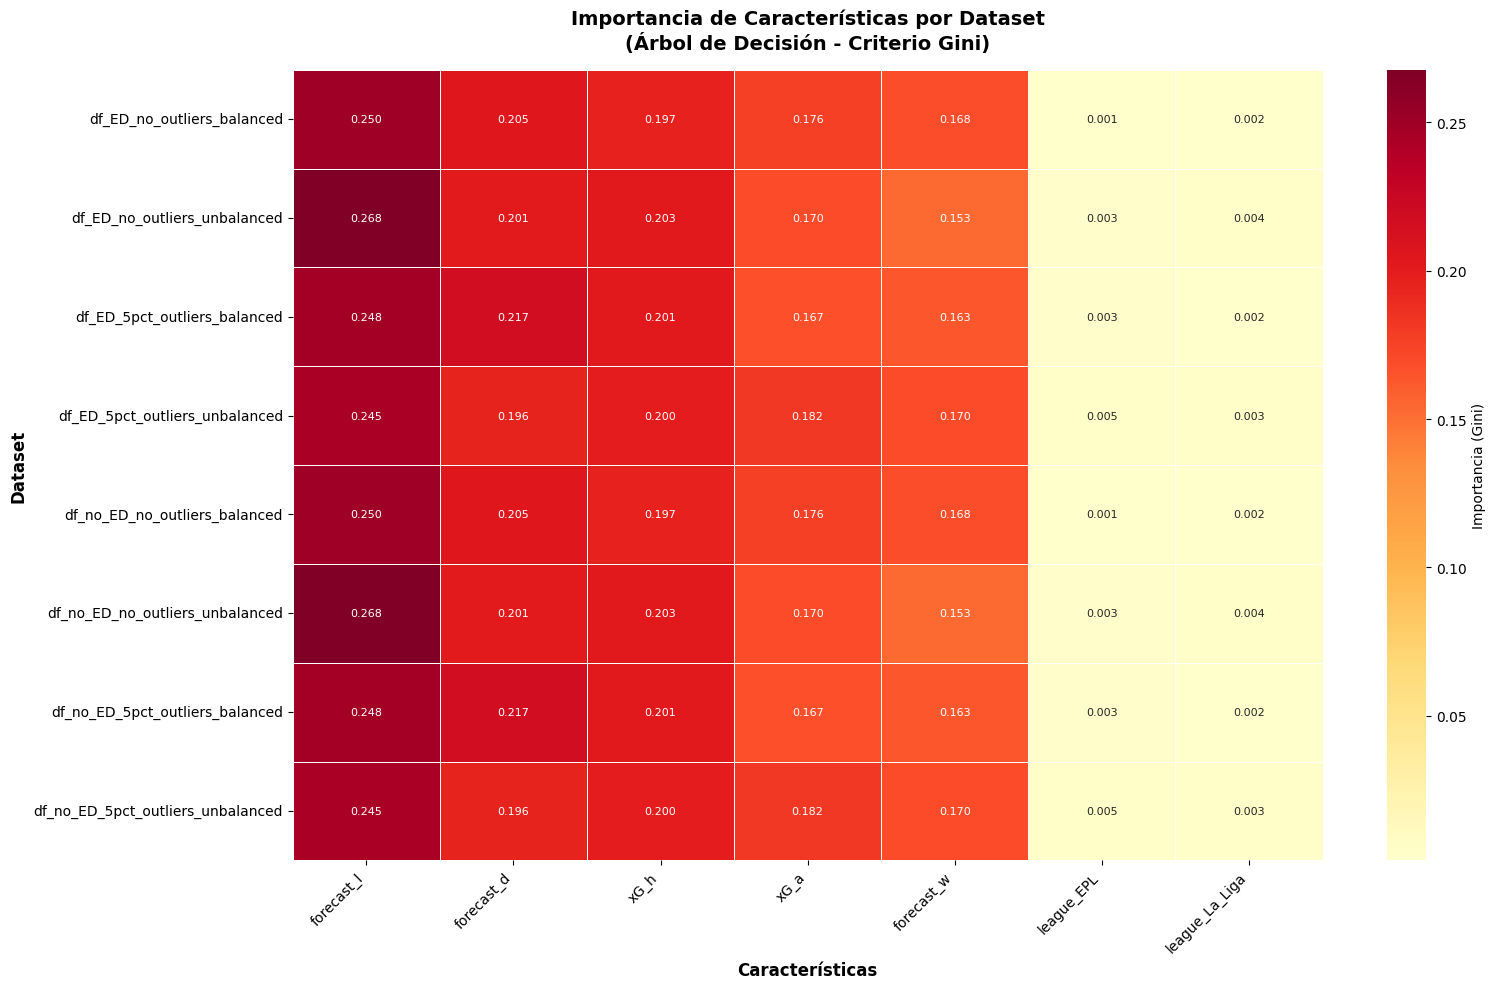

In [ ]:
# Crear DataFrame con importancia de todas las características
df_feature_importance = pd.DataFrame(feature_importance_all, index=features).T

# Calcular importancia promedio
importance_mean = df_feature_importance.mean().sort_values(ascending=False)

# Heatmap de importancia por datase
fig, ax = plt.subplots(figsize=(16, 10))

# Se seleccionan las 20 características con mayor importancia promedio
top_20_features = importance_mean.head(20).index
df_importance_top20 = df_feature_importance[top_20_features]

# Se genera el mapa de calor (heatmap)
sns.heatmap(df_importance_top20, annot=True, fmt='.3f', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label': 'Importancia (Gini)'},
            ax=ax, annot_kws={'fontsize': 8})

ax.set_xlabel('Características', fontsize=12, fontweight='bold')
ax.set_ylabel('Dataset', fontsize=12, fontweight='bold')
ax.set_title('Importancia de Características por Dataset\n(Árbol de Decisión - Criterio Gini)',
             fontsize=14, fontweight='bold', pad=15)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 👆 Gráficos de arbol por caso usando el criterio Gini

In [ ]:
# entrenamos usando el criterio Gini
tree_results = {}

for name, data in train_test_data.items():
    tree = DecisionTreeClassifier(
        criterion='gini',  # Criterio Gini explícito
        random_state=123,
        max_depth=5,  # Limitamos la profundidad
        min_samples_split=20,
        min_samples_leaf=10
    )
    tree.fit(data["X_train"], data["y_train"])

    # Predicciones
    y_pred = tree.predict(data["X_test"])

    # Reportes de clasificación
    report = classification_report(data["y_test"], y_pred, output_dict=True)

    # Guardar resultados
    tree_results[name] = {
        "tree": tree,
        "Accuracy": report["accuracy"],
        "Precision": report["weighted avg"]["precision"],
        "Recall": report["weighted avg"]["recall"],
        "F1_score": report["weighted avg"]["f1-score"],
        "depth": tree.get_depth(),
        "n_leaves": tree.get_n_leaves(),
        "X_train": data["X_train"],
        "X_test": data["X_test"],
        "y_train": data["y_train"],
        "y_test": data["y_test"]
    }

# Árboles simplificados (profundidad=4)


print("Generando árboles SIMPLIFICADOS (profundidad=4)...\n")

for name, results in tree_results.items():
    print(f"\nGenerando árbol simplificado para: {name}\n")

    # Entrenar árbol simplificado
    tree_simple = DecisionTreeClassifier(
        criterion='gini',
        max_depth=4,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=123
    )

    tree_simple.fit(results['X_train'], results['y_train'])

    # Evaluar
    y_pred_simple = tree_simple.predict(results['X_test'])
    from sklearn.metrics import classification_report
    report_simple = classification_report(results['y_test'], y_pred_simple, output_dict=True)

    # Visualizar
    fig, ax = plt.subplots(figsize=(22, 14))

    plot_tree(tree_simple,
              feature_names=features,
              filled=True,
              rounded=True,
              fontsize=11,
              ax=ax,
              proportion=True,
              precision=3,
              impurity=True)

    plt.title(f'Árbol de Decisión Simplificado (Criterio Gini, Profundidad=3)\n{name}\n' +
              f'F1-Score: {report_simple["weighted avg"]["f1-score"]:.4f} | ' +
              f'Accuracy: {report_simple["accuracy"]:.4f}',
              fontsize=16, fontweight='bold', pad=20)

    plt.tight_layout()

    # Mostramos los arboles
    plt.show()
    plt.close()

## **⛺ KNN**

### Entrenamiento y metricas

In [ ]:
# Dict para guardar resultados globales
knn_results = {}

for dataset_name, data in train_test_data.items():

    # Entrenar KNN
    knn = KNeighborsClassifier(n_neighbors=5)
    knn.fit(data["X_train"], data["y_train"])

    # Predicciones
    y_pred = knn.predict(data["X_test"])


    # Generar el reporte de clasificación
    report_scaled = classification_report(data["y_test"], y_pred, output_dict=True)

    # Guardar resultados
    knn_results[dataset_name] = {
        "knn": knn,
        "y_pred": y_pred,
        "Accuracy": report["accuracy"],
        "Precision": report["weighted avg"]["precision"],
        "Recall": report["weighted avg"]["recall"],
        "F1_score": report["weighted avg"]["f1-score"]
    }

In [ ]:
# Imprimir reportes
for dataset_name, results in knn_results.items():
    print(f"\n===== Dataset: {dataset_name} =====")
    print("KNN:")
    print(classification_report(
        train_test_data[dataset_name]["y_test"],
        results["y_pred"]
    ))


===== Dataset: df_ED_no_outliers_balanced =====
KNN:
              precision    recall  f1-score   support

           0       0.37      0.44      0.40       710
           1       0.45      0.47      0.46       882
           2       0.46      0.45      0.46       721
           3       0.59      0.41      0.48       561

    accuracy                           0.45      2874
   macro avg       0.47      0.44      0.45      2874
weighted avg       0.46      0.45      0.45      2874


===== Dataset: df_ED_no_outliers_unbalanced =====
KNN:
              precision    recall  f1-score   support

           0       0.40      0.56      0.47       739
           1       0.45      0.44      0.45       697
           2       0.42      0.34      0.38       504
           3       0.44      0.20      0.27       318

    accuracy                           0.42      2258
   macro avg       0.43      0.39      0.39      2258
weighted avg       0.43      0.42      0.41      2258


===== Dataset: df_E

### 🎯 Resultados

In [ ]:
# Crear un DataFrame a partir del diccionario para visualización
results_knn = pd.DataFrame.from_dict(knn_results, orient='index')

# Mostrar tabla ordenada por indices
results_knn = results_knn.reset_index().rename(columns={'index': 'Dataset'})
results_knn.drop(columns=['knn','y_pred'], inplace=True) # Eliminamos columnas que no queremos visualizar
results_knn = results_knn.sort_index()

# Mostrar
results_knn

,Dataset,Accuracy,Precision,Recall,F1_score
0,df_ED_no_outliers_balanced,0.459564,0.475906,0.459564,0.442893
1,df_ED_no_outliers_unbalanced,0.459564,0.475906,0.459564,0.442893
2,df_ED_5pct_outliers_balanced,0.459564,0.475906,0.459564,0.442893
3,df_ED_5pct_outliers_unbalanced,0.459564,0.475906,0.459564,0.442893
4,df_no_ED_no_outliers_balanced,0.459564,0.475906,0.459564,0.442893
5,df_no_ED_no_outliers_unbalanced,0.459564,0.475906,0.459564,0.442893
6,df_no_ED_5pct_outliers_balanced,0.459564,0.475906,0.459564,0.442893
7,df_no_ED_5pct_outliers_unbalanced,0.459564,0.475906,0.459564,0.442893


### 👆 Gráfico de los vecinos

In [ ]:
# Fronteras de Decisión con PCA (2D) - PARA CADA MODELO

def plot_knn_decision_boundary(X_train, X_test, y_train, y_test, knn_model,
                                dataset_name, n_neighbors=5):

    # Reducir dimensionalidad a 2D con PCA
    pca = PCA(n_components=2)
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    # Entrenar KNN en el espacio reducido
    knn_pca = KNeighborsClassifier(n_neighbors=n_neighbors)
    knn_pca.fit(X_train_pca, y_train)

    # Crear mesh para visualizar fronteras
    h = 0.02  # tamaño del paso en el mesh
    x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
    y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    # Predecir para cada punto del mesh
    Z = knn_pca.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Obtener clases únicas
    classes = np.unique(y_train)
    n_classes = len(classes)

    # Configurar colores
    cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'][:n_classes])
    cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'][:n_classes])

    # Crear figura
    fig, ax = plt.subplots(figsize=(12, 9))

    # Graficar fronteras de decisión
    ax.contourf(xx, yy, Z, alpha=0.4, cmap=cmap_light)

    # Graficar puntos de entrenamiento
    scatter_train = ax.scatter(X_train_pca[:, 0], X_train_pca[:, 1],
                               c=y_train, cmap=cmap_bold,
                               edgecolor='black', s=50, alpha=0.7,
                               label='Entrenamiento')

    # Graficar puntos de prueba
    scatter_test = ax.scatter(X_test_pca[:, 0], X_test_pca[:, 1],
                              c=y_test, cmap=cmap_bold,
                              edgecolor='yellow', s=100, alpha=0.9,
                              marker='^', linewidths=2,
                              label='Prueba')

    # Calcular varianza explicada
    var_explained = pca.explained_variance_ratio_

    ax.set_xlabel(f'PC1 ({var_explained[0]:.2%} varianza)', fontsize=12, fontweight='bold')
    ax.set_ylabel(f'PC2 ({var_explained[1]:.2%} varianza)', fontsize=12, fontweight='bold')
    ax.set_title(f'KNN - Fronteras de Decisión (k={n_neighbors})\n{dataset_name}',
                 fontsize=14, fontweight='bold', pad=15)

    legend1 = ax.legend(*scatter_train.legend_elements(),
                       title="Clases", loc="upper left")
    ax.add_artist(legend1)
    ax.legend(loc="upper right")

    ax.grid(alpha=0.3, linestyle='--')

    plt.tight_layout()
    return fig, pca

# Generar gráficos para cada dataset

print("\nGENERANDO FRONTERAS DE DECISIÓN PARA KNN\n")


for dataset_name, results in knn_results.items():
    print(f"\n🎯 Generando visualización para: {dataset_name}\n")

    # Obtener datos del entrenamiento
    train_data = train_test_data[dataset_name]

    fig, pca = plot_knn_decision_boundary(
        train_data["X_train"],
        train_data["X_test"],
        train_data["y_train"],
        train_data["y_test"],
        results["knn"],
        dataset_name,
        n_neighbors=5
    )

    plt.show()
    plt.close()

## **🏹 SVM**

### Entrenamiento y metricas

In [ ]:
# Dict para guardar resultados globales
svm_results = {}

for dataset_name, data in train_test_data.items():

    # Entrenar SVM
    svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=123)
    svm_model.fit(data["X_train"], data["y_train"])

    # Predicciones
    y_pred = svm_model.predict(data["X_test"])

    # reporte
    report = classification_report(data["y_test"], y_pred, output_dict=True)

    # Guardar resultados
    svm_results[dataset_name] = {
        "svm": svm_model,
        "y_pred": y_pred,
        "Accuracy": report["accuracy"],
        "Precision": report["weighted avg"]["precision"],
        "Recall": report["weighted avg"]["recall"],
        "F1_score": report["weighted avg"]["f1-score"]
    }

In [ ]:
# Imprimir reportes
for dataset_name, results in svm_results.items():
    print(f"\n===== Dataset: {dataset_name} =====")
    print("SVM")
    print(classification_report(
        train_test_data[dataset_name]["y_test"],
        results["y_pred"]
    ))



===== Dataset: df_ED_no_outliers_balanced =====
SVM
              precision    recall  f1-score   support

           0       0.39      0.12      0.19       710
           1       0.43      0.68      0.53       882
           2       0.43      0.63      0.52       721
           3       0.64      0.24      0.35       561

    accuracy                           0.45      2874
   macro avg       0.47      0.42      0.40      2874
weighted avg       0.46      0.45      0.41      2874


===== Dataset: df_ED_no_outliers_unbalanced =====
SVM
              precision    recall  f1-score   support

           0       0.41      0.53      0.47       739
           1       0.45      0.53      0.49       697
           2       0.47      0.44      0.46       504
           3       0.67      0.01      0.01       318

    accuracy                           0.44      2258
   macro avg       0.50      0.38      0.35      2258
weighted avg       0.47      0.44      0.41      2258


===== Dataset: df_ED_

### 🎯 Resultados

In [ ]:
# Crear un DataFrame a partir del diccionario para visualización
results_df_svm = pd.DataFrame.from_dict(svm_results, orient='index')

# Mostrar tabla ordenada por indices
results_df_svm = results_df_svm.reset_index().rename(columns={'index': 'Dataset'})
results_df_svm.drop(columns=['svm','y_pred'], inplace=True) # Eliminamos columnas que no queremos visualizar

# Mostrar
results_df_svm

,Dataset,Accuracy,Precision,Recall,F1_score
0,df_ED_no_outliers_balanced,0.445372,0.463019,0.445372,0.406486
1,df_ED_no_outliers_unbalanced,0.437998,0.472271,0.437998,0.405723
2,df_ED_5pct_outliers_balanced,0.448883,0.468981,0.448883,0.420680
3,df_ED_5pct_outliers_unbalanced,0.456996,0.497070,0.456996,0.442311
4,df_no_ED_no_outliers_balanced,0.440153,0.459081,0.440153,0.405252
5,df_no_ED_no_outliers_unbalanced,0.434898,0.472299,0.434898,0.413696
6,df_no_ED_5pct_outliers_balanced,0.443805,0.464456,0.443805,0.418657
7,df_no_ED_5pct_outliers_unbalanced,0.455285,0.494074,0.455285,0.446217


### 👆  Regiones de decisión

REGIONES DE DECISIÓN PARA SVM

🎯 df_ED_no_outliers_balanced



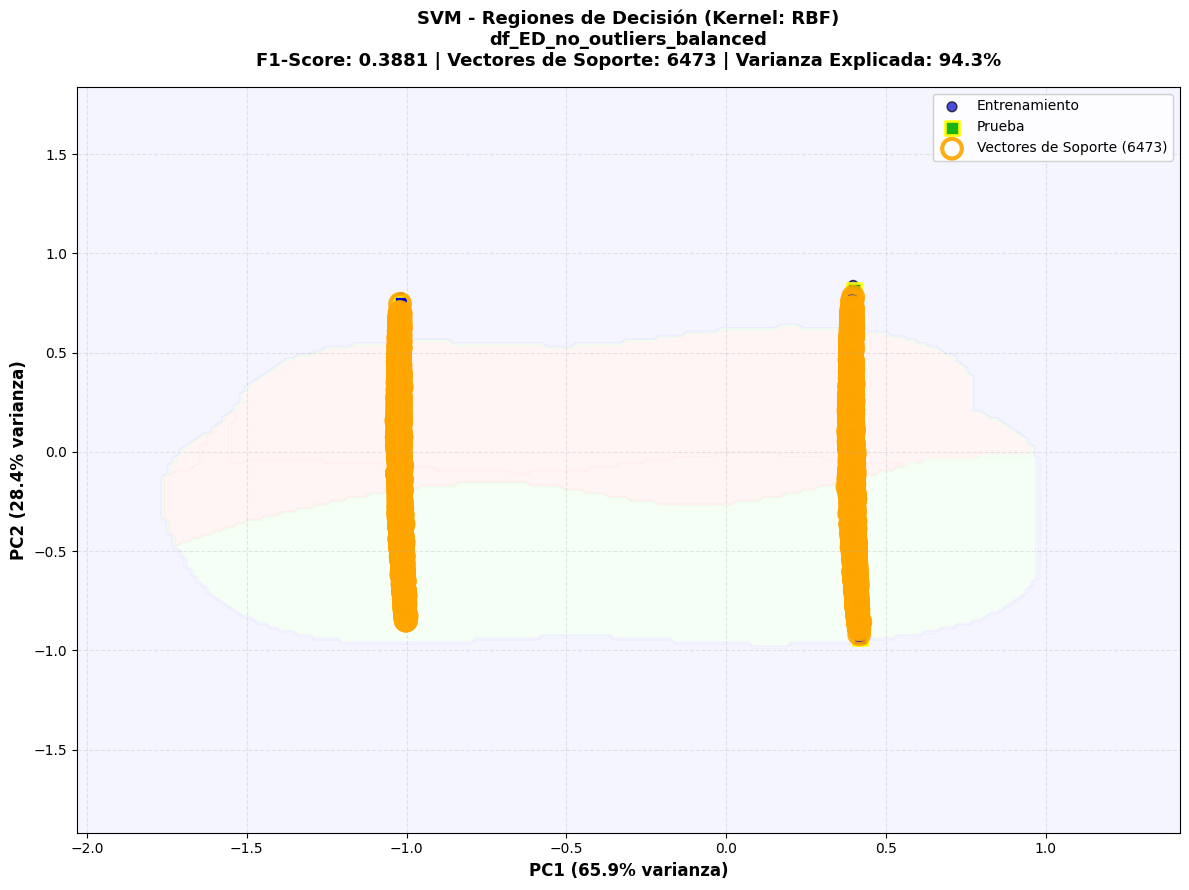


🎯 df_ED_no_outliers_unbalanced



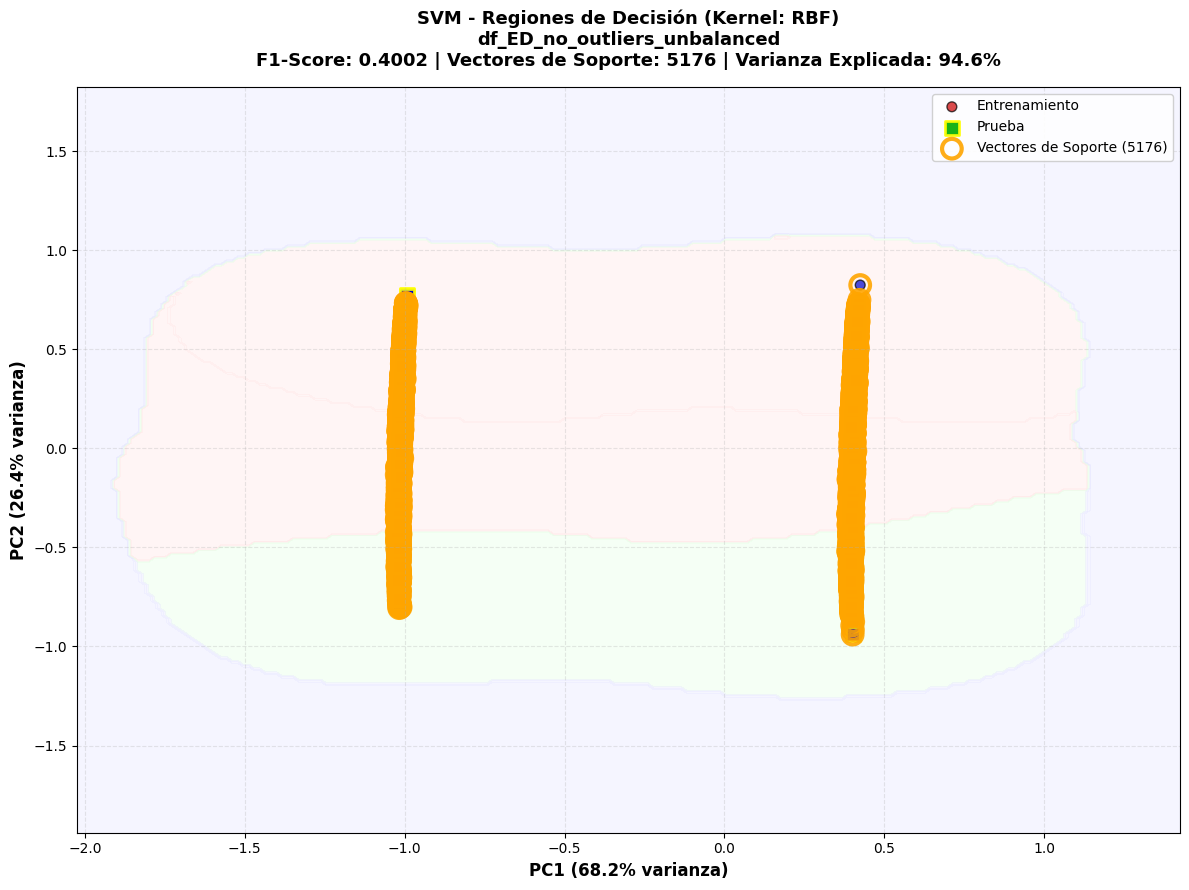


🎯 df_ED_5pct_outliers_balanced



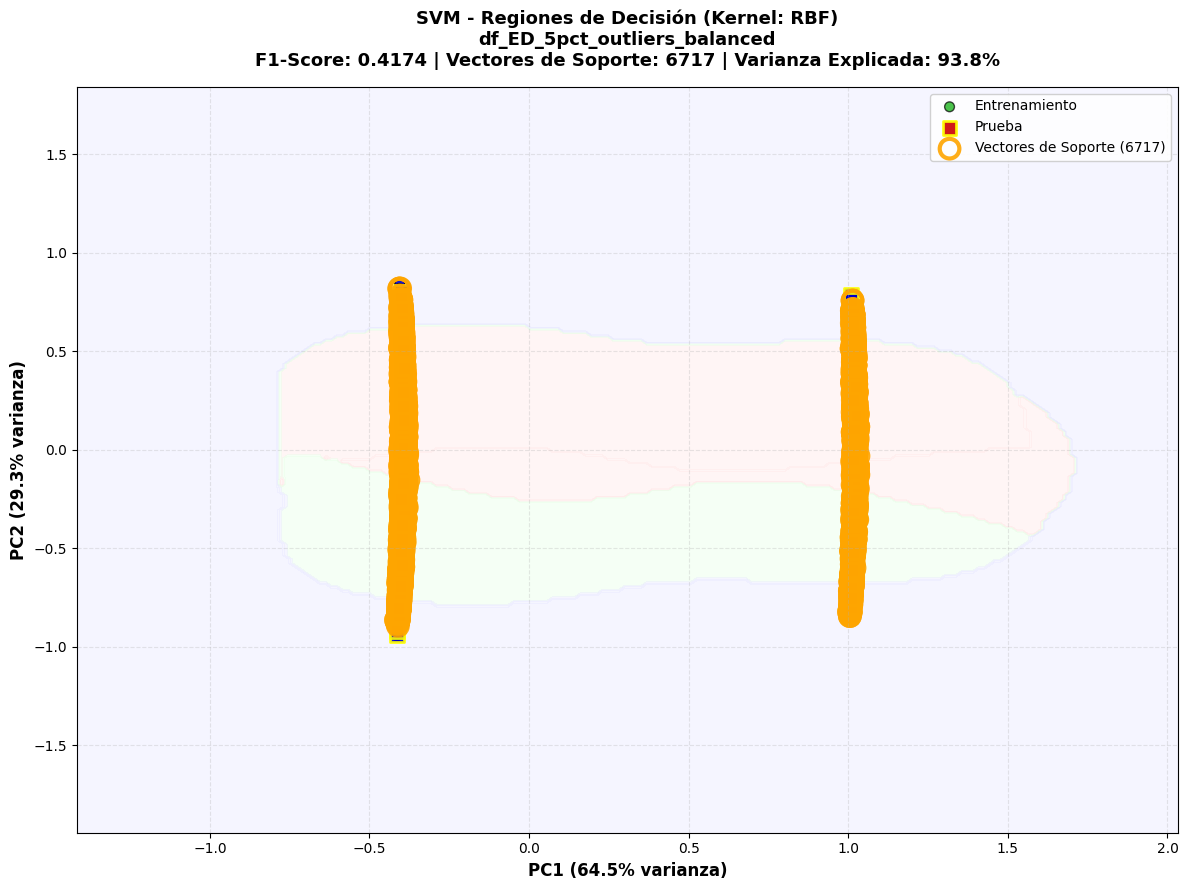


🎯 df_ED_5pct_outliers_unbalanced



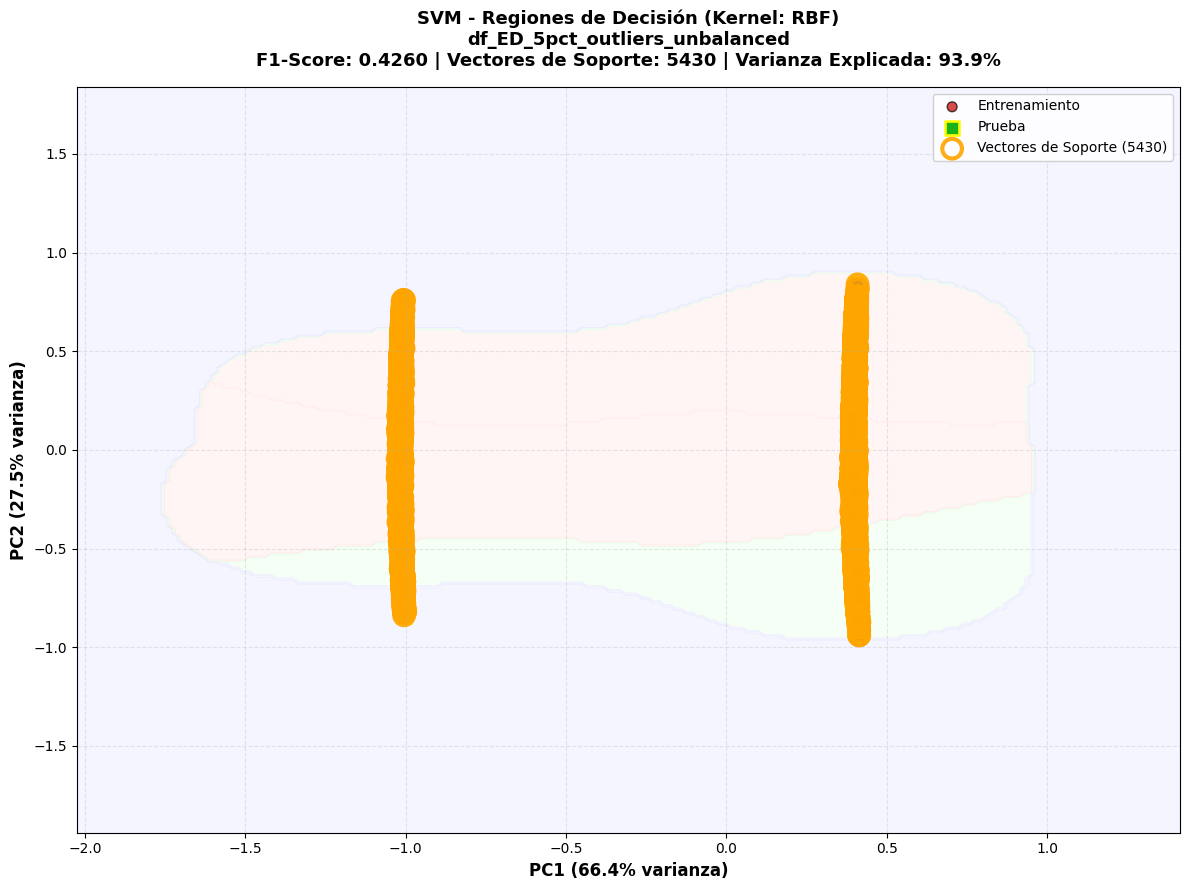


🎯 df_no_ED_no_outliers_balanced



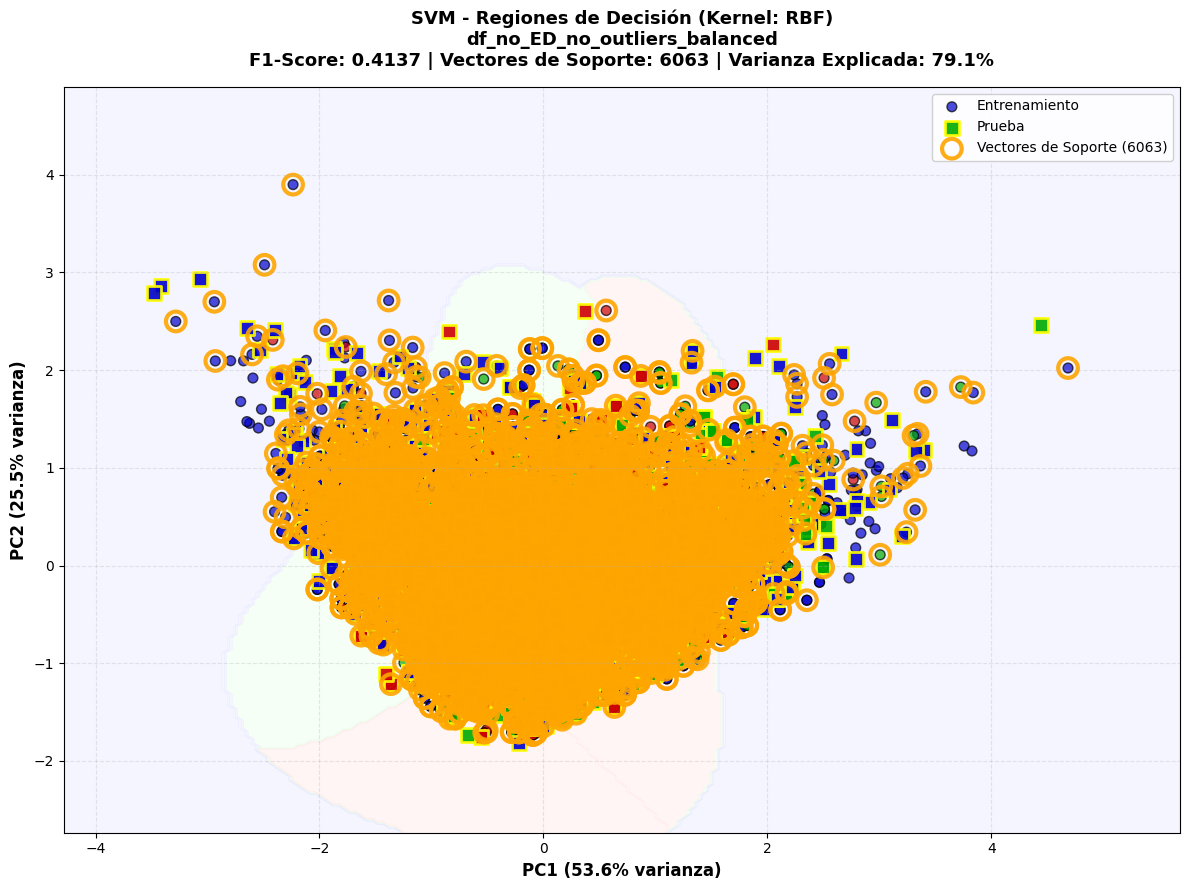


🎯 df_no_ED_no_outliers_unbalanced



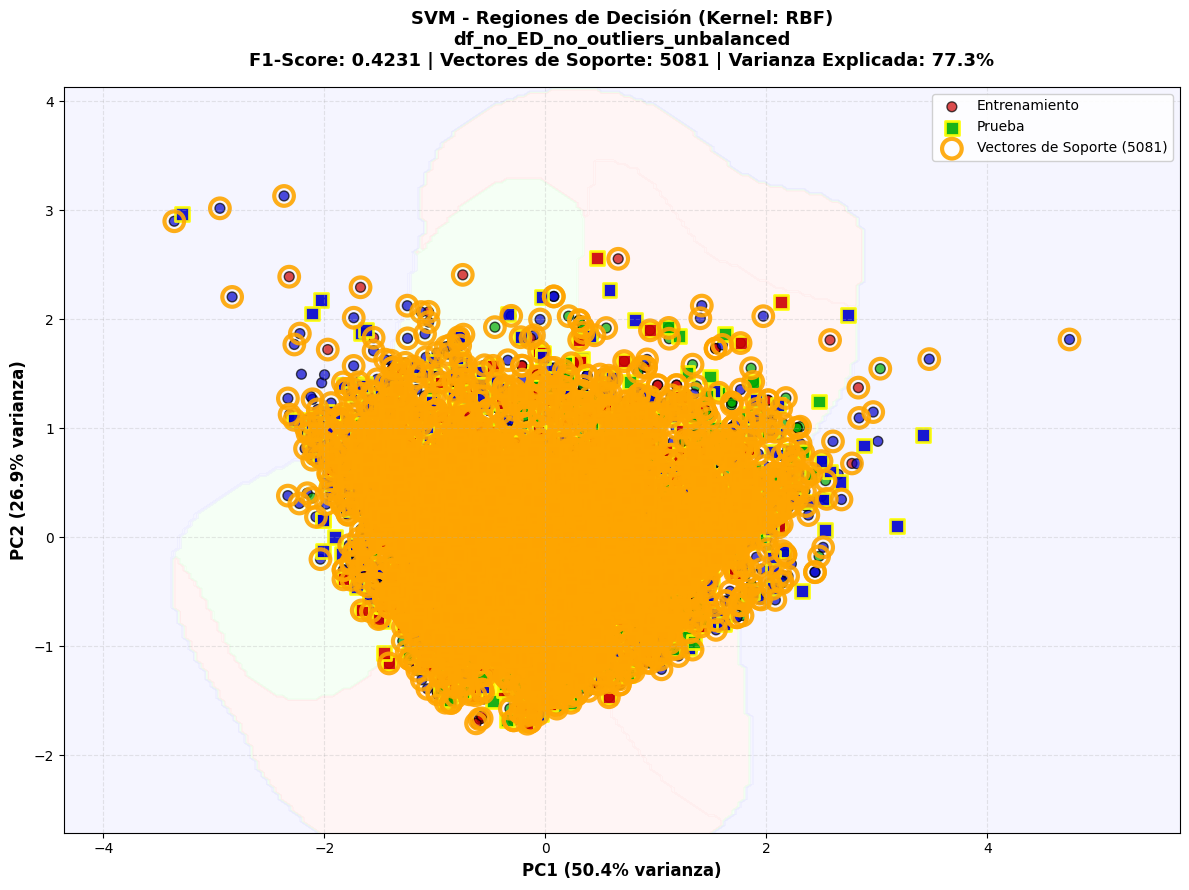


🎯 df_no_ED_5pct_outliers_balanced



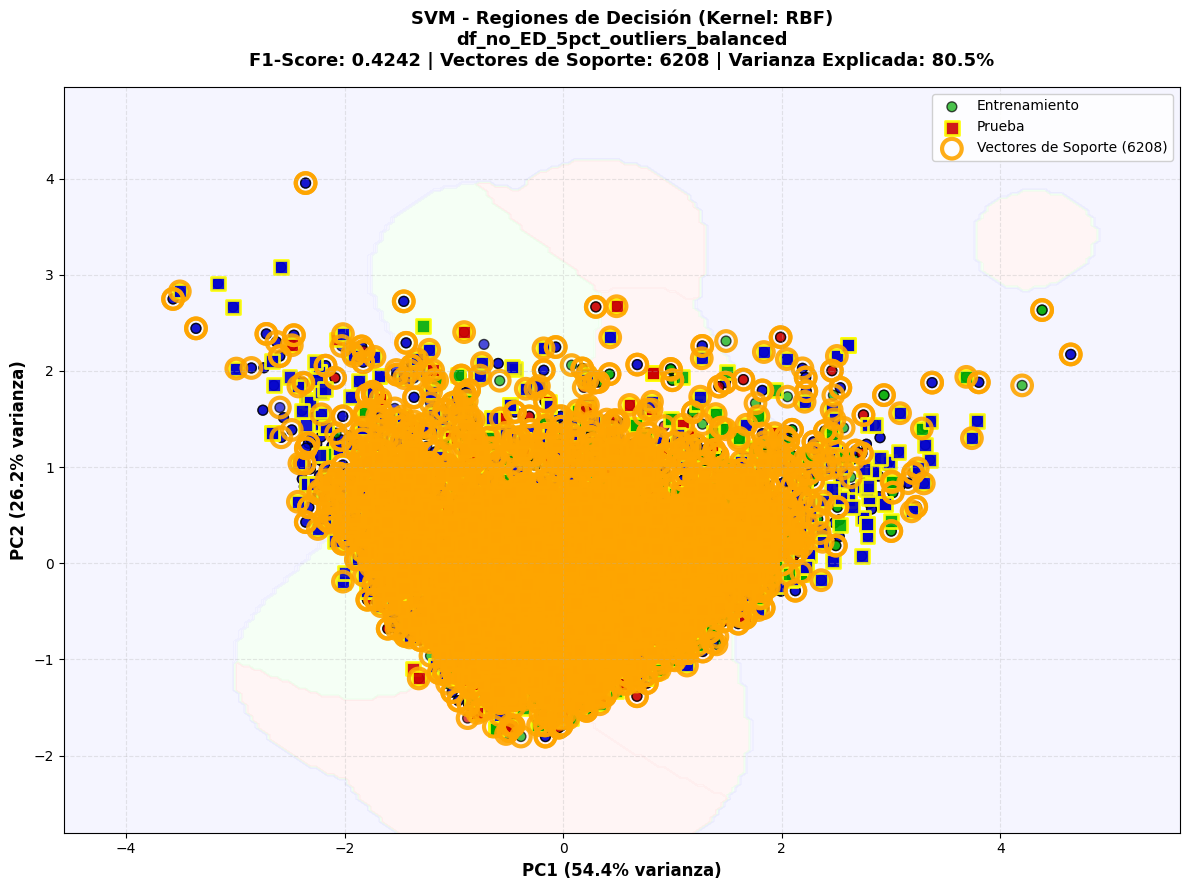


🎯 df_no_ED_5pct_outliers_unbalanced



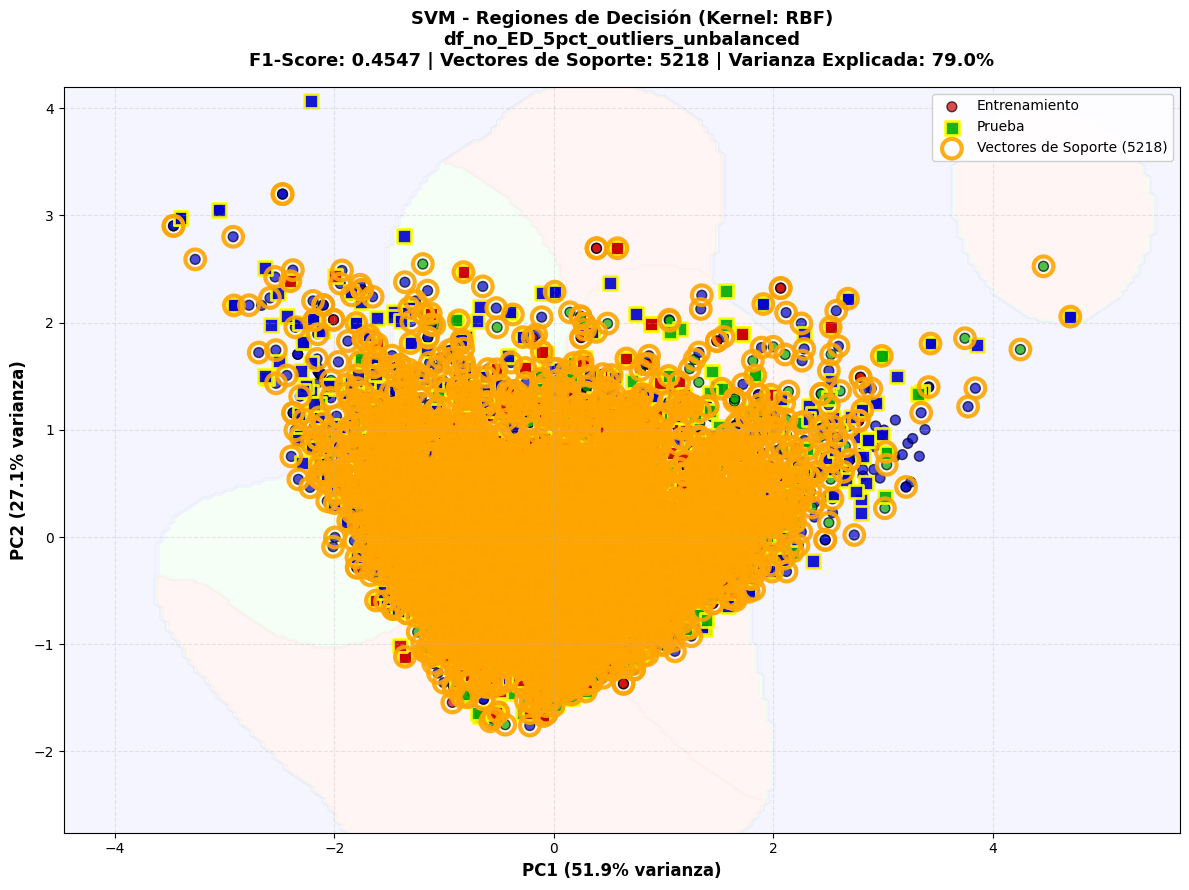

In [ ]:
def plot_svm_decision_regions_fixed(X_train, X_test, y_train, y_test, dataset_name, kernel="rbf"):

    # PCA a 2D
    pca = PCA(n_components=2)
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    # Entrenar SVM
    svm_model = SVC(kernel=kernel, C=1.0, gamma="scale", random_state=123)
    svm_model.fit(X_train_pca, y_train)

    # Crear mesh con resolución fija
    resolution = 200

    x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
    y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1

    x_range = np.linspace(x_min, x_max, resolution)
    y_range = np.linspace(y_min, y_max, resolution)
    xx, yy = np.meshgrid(x_range, y_range)

    # Predecir
    Z = svm_model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    classes = np.unique(y_train)
    n_classes = len(classes)

    cmap_light = ListedColormap(['#FFE6E6', '#E6FFE6', '#E6E6FF'][:n_classes])
    cmap_bold = ListedColormap(['#CC0000', '#00AA00', '#0000CC'][:n_classes])

    # Crear figura
    fig, ax = plt.subplots(figsize=(12, 9))

    # Regiones de decisión
    ax.contourf(xx, yy, Z, alpha=0.4, cmap=cmap_light)

    # Puntos de entrenamiento
    ax.scatter(X_train_pca[:, 0], X_train_pca[:, 1],
              c=y_train, cmap=cmap_bold,
              edgecolor='black', s=50, alpha=0.7,
              linewidths=1,
              label='Entrenamiento')

    # Puntos de prueba
    ax.scatter(X_test_pca[:, 0], X_test_pca[:, 1],
              c=y_test, cmap=cmap_bold,
              edgecolor='yellow', s=100, alpha=0.9,
              marker='s',
              linewidths=2,
              label='Prueba')

    # Vectores de soporte
    if hasattr(svm_model, 'support_vectors_'):
        sv = svm_model.support_vectors_
        ax.scatter(sv[:, 0], sv[:, 1],
                  s=200, facecolors='none',
                  edgecolors='orange', alpha=0.9,
                  linewidths=3,
                  label=f'Vectores de Soporte ({len(sv)})')

    # Calcular métricas
    y_pred = svm_model.predict(X_test_pca)
    f1 = f1_score(y_test, y_pred, average='weighted')

    # Varianza explicada
    var_exp = pca.explained_variance_ratio_

    # Etiquetas y título
    ax.set_xlabel(f'PC1 ({var_exp[0]:.1%} varianza)', fontsize=12, fontweight='bold')
    ax.set_ylabel(f'PC2 ({var_exp[1]:.1%} varianza)', fontsize=12, fontweight='bold')

    n_sv = len(svm_model.support_vectors_) if hasattr(svm_model, 'support_vectors_') else 0
    ax.set_title(f'SVM - Regiones de Decisión (Kernel: {kernel.upper()})\n' +
                 f'{dataset_name}\n' +
                 f'F1-Score: {f1:.4f} | Vectores de Soporte: {n_sv} | ' +
                 f'Varianza Explicada: {sum(var_exp):.1%}',
                 fontsize=13, fontweight='bold', pad=15)

    ax.legend(loc='best', fontsize=10, framealpha=0.9)
    ax.grid(alpha=0.3, linestyle='--')

    plt.tight_layout()
    return fig, svm_model, pca

print("REGIONES DE DECISIÓN PARA SVM")

for dataset_name, results in svm_results.items():
    print(f"\n🎯 {dataset_name}\n")

    train_data = train_test_data[dataset_name]

    fig, svm_pca, pca = plot_svm_decision_regions_fixed(
          train_data["X_train"],
          train_data["X_test"],
          train_data["y_train"],
          train_data["y_test"],
          dataset_name,
          kernel="rbf"
        )

    plt.show()
    plt.close()

## **🧠 Redes Neuronales**

### Entrenamiento y metricas

In [ ]:

# Dict para guardar resultados globales
nn_results = {}

for dataset_name, data in train_test_data.items():
    print(f"\n===== Dataset: {dataset_name} =====")

    # Construir arquitectura profunda
    nn_deep = Sequential([
        Dense(128, activation="relu", input_shape=(data["X_train"].shape[1],)),
        BatchNormalization(),
        Dropout(0.3),

        Dense(64, activation="relu"),
        BatchNormalization(),
        Dropout(0.3),

        Dense(32, activation="relu"),
        BatchNormalization(),
        Dropout(0.2),

        Dense(16, activation="relu"),
        Dense(4, activation="softmax")  # 4 clases
    ])

    # Compilación
    nn_deep.compile(optimizer="adam",
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])

    # Callbacks
    early_stop = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)

    # Entrenamiento
    history = nn_deep.fit(data["X_train"], data["y_train"],
                          validation_split=0.2,
                          epochs=200,
                          batch_size=64,
                          callbacks=[early_stop, reduce_lr],
                          verbose=0)

    # Predicciones
    y_pred_nn = nn_deep.predict(data["X_test"])
    y_pred_nn_classes = np.argmax(y_pred_nn, axis=1)

    # Reporte
    report = classification_report(data["y_test"], y_pred_nn_classes, output_dict=True)

    # Guardar resultados
    nn_results[dataset_name] = {
        "model": nn_deep,
        "history": history,
        "y_pred_classes": y_pred_nn_classes,
        "report": report,
        "Accuracy": report["accuracy"],
        "Precision": report["weighted avg"]["precision"],
        "Recall": report["weighted avg"]["recall"],
        "F1_score": report["weighted avg"]["f1-score"]
    }

    # Imprimir reporte
    print("Red neuronal profunda:")
    print(classification_report(data["y_test"], y_pred_nn_classes))



===== Dataset: df_ED_no_outliers_balanced =====


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Red neuronal profunda:
              precision    recall  f1-score   support

           0       0.33      0.18      0.23       710
           1       0.44      0.59      0.50       882
           2       0.43      0.65      0.52       721
           3       0.60      0.25      0.35       561

    accuracy                           0.43      2874
   macro avg       0.45      0.42      0.40      2874
weighted avg       0.44      0.43      0.41      2874


===== Dataset: df_ED_no_outliers_unbalanced =====


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Red neuronal profunda:
              precision    recall  f1-score   support

           0       0.42      0.47      0.44       739
           1       0.44      0.57      0.50       697
           2       0.47      0.46      0.46       504
           3       0.70      0.07      0.12       318

    accuracy                           0.44      2258
   macro avg       0.51      0.39      0.38      2258
weighted avg       0.47      0.44      0.42      2258


===== Dataset: df_ED_5pct_outliers_balanced =====


...

71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Red neuronal profunda:
              precision    recall  f1-score   support

           0       0.41      0.43      0.42       739
           1       0.45      0.54      0.49       697
           2       0.44      0.47      0.46       504
           3       0.55      0.22      0.31       318

    accuracy                           0.44      2258
   macro avg       0.47      0.41      0.42      2258
weighted avg       0.45      0.44      0.44      2258


===== Dataset: df_no_ED_5pct_outliers_balanced =====


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Red neuronal profunda:
              precision    recall  f1-score   support

           0       0.35      0.21      0.26       718
           1       0.43      0.59      0.50       894
           2       0.44      0.58      0.50       735
           3       0.64      0.34      0.44       607

    accuracy                           0.45      2954
   macro avg       0.47      0.43      0.43      2954
weighted avg       0.46      0.45      0.43      2954


===== Dataset: df_no_ED_5pct_outliers_unbalanced =====


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


74/74 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Red neuronal profunda:
              precision    recall  f1-score   support

           0       0.43      0.43      0.43       747
           1       0.46      0.57      0.51       708
           2       0.46      0.45      0.46       518
           3       0.65      0.35      0.46       364

    accuracy                           0.47      2337
   macro avg       0.50      0.45      0.46      2337
weighted avg       0.48      0.47      0.46      2337



### 🎯 Resultados

In [ ]:
# Crear un DataFrame a partir del diccionario para visualización
nn_result_df = pd.DataFrame.from_dict(nn_results, orient='index')

# Mostrar tabla ordenada por indices
nn_result_df = nn_result_df.reset_index().rename(columns={'index': 'Dataset'})
nn_result_df.drop(columns=['model','history','y_pred_classes','report'], inplace=True) # Eliminamos columnas que no queremos visualizar

# Mostrar
nn_result_df

,Dataset,Accuracy,Precision,Recall,F1_score
0,df_ED_no_outliers_balanced,0.434934,0.443278,0.434934,0.410122
1,df_ED_no_outliers_unbalanced,0.440655,0.474888,0.440655,0.417817
2,df_ED_5pct_outliers_balanced,0.454299,0.466532,0.454299,0.430882
3,df_ED_5pct_outliers_unbalanced,0.464698,0.476766,0.464698,0.463086
4,df_no_ED_no_outliers_balanced,0.438065,0.452587,0.438065,0.413805
5,df_no_ED_no_outliers_unbalanced,0.442870,0.451813,0.442870,0.435719
6,df_no_ED_5pct_outliers_balanced,0.445159,0.456864,0.445159,0.430793
7,df_no_ED_5pct_outliers_unbalanced,0.465982,0.479482,0.465982,0.464036


## **📊 Diagramas**

### Diagrama de barras con el F1-Score máximo por algoritmo

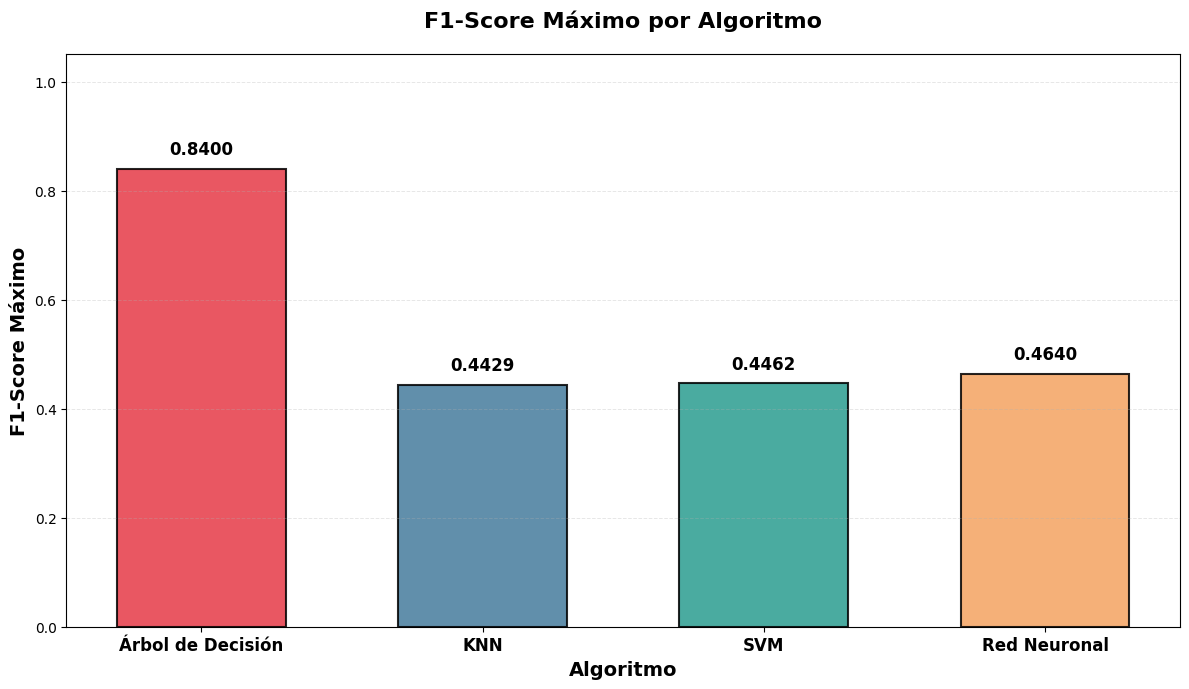

In [ ]:
# Diccionario con los dataframes de resultados y nombres de modelos
results_dict = {
    'Árbol de Decisión': results_arbol,
    'KNN': results_knn,
    'SVM': results_df_svm,
    'Red Neuronal': nn_result_df
}

# Calcular F1-Score máximo para cada modelo
f1_scores_max = {
    'modelo': [],
    'f1_max': [],
    'dataset_mejor': []
}

for modelo_name, df_resultado in results_dict.items():
    # Obtener el F1_Score máximo
    idx_max = df_resultado['F1_score'].idxmax()
    f1_max = df_resultado.loc[idx_max, 'F1_score']
    dataset_mejor = df_resultado.loc[idx_max, 'Dataset']

    f1_scores_max['modelo'].append(modelo_name)
    f1_scores_max['f1_max'].append(f1_max)
    f1_scores_max['dataset_mejor'].append(dataset_mejor)

# Crear el gráfico de barras
fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(f1_scores_max['modelo']))
colores = ['#E63946', '#457B9D', '#2A9D8F', '#F4A261']

bars = ax.bar(x, f1_scores_max['f1_max'], width=0.6,
              color=colores, edgecolor='black', linewidth=1.5, alpha=0.85)

# Personalización del gráfico
ax.set_xlabel('Algoritmo', fontsize=14, fontweight='bold')
ax.set_ylabel('F1-Score Máximo', fontsize=14, fontweight='bold')
ax.set_title('F1-Score Máximo por Algoritmo',
             fontsize=16, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(f1_scores_max['modelo'], fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
ax.set_ylim([0, 1.05])

# Añadir valores en las barras
for i, bar in enumerate(bars):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
            f'{height:.4f}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### Diagrama de barras con el F1-Score medio por normalización y algoritmo

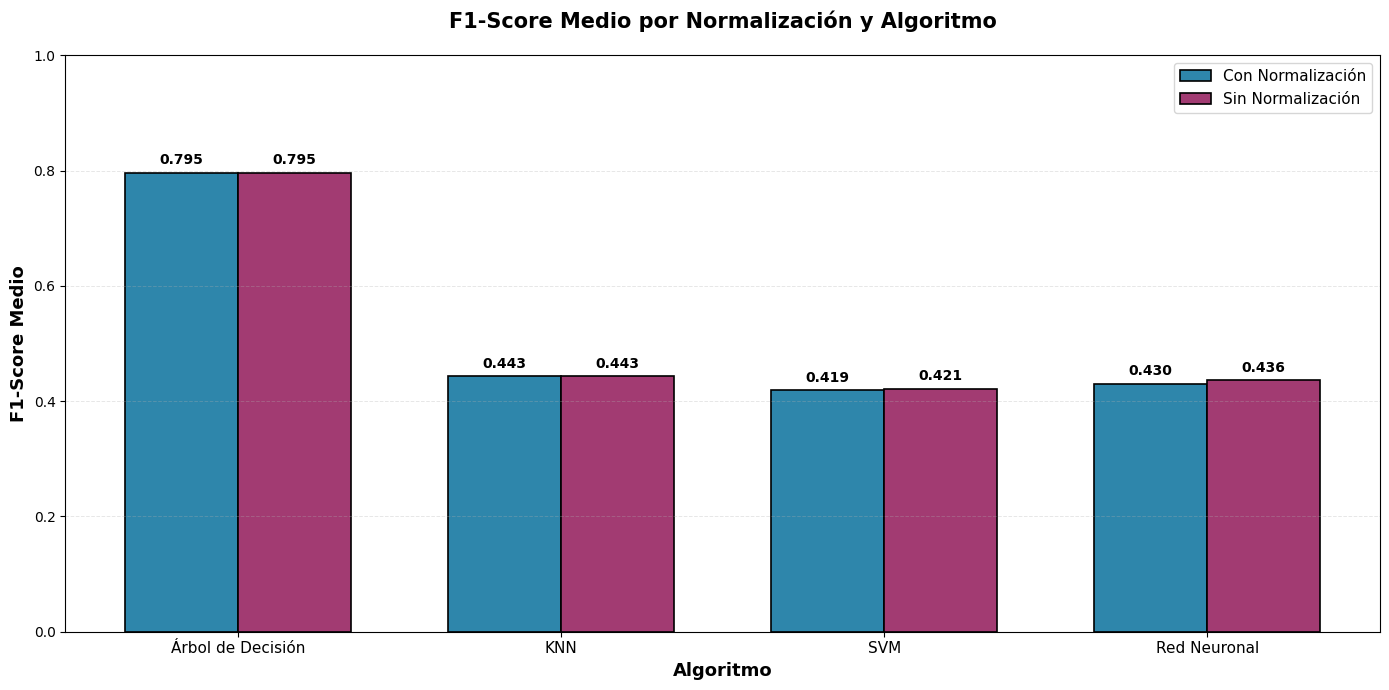

In [ ]:
# Nombres de los datasets normalizados (con ED)
datasets_normalizados = [
    "df_ED_no_outliers_balanced",
    "df_ED_no_outliers_unbalanced",
    "df_ED_5pct_outliers_balanced",
    "df_ED_5pct_outliers_unbalanced"
]

# Nombres de los datasets no normalizados (sin ED)
datasets_no_normalizados = [
    "df_no_ED_no_outliers_balanced",
    "df_no_ED_no_outliers_unbalanced",
    "df_no_ED_5pct_outliers_balanced",
    "df_no_ED_5pct_outliers_unbalanced"
]

# Diccionario con los dataframes de resultados y nombres de modelos
results_dict = {
    'Árbol de Decisión': results_arbol,
    'KNN': results_knn,
    'SVM': results_df_svm,
    'Red Neuronal': nn_result_df
}

# Calcular F1_Score medio para cada modelo
f1_scores = {
    'modelo': [],
    'normalizado': [],
    'no_normalizado': []
}

for modelo_name, df_resultado in results_dict.items():
    # F1_Score medio con normalización (datasets con ED)
    f1_norm = df_resultado[df_resultado['Dataset'].isin(datasets_normalizados)]['F1_score'].mean()

    # F1_Score medio sin normalización (datasets sin ED)
    f1_no_norm = df_resultado[df_resultado['Dataset'].isin(datasets_no_normalizados)]['F1_score'].mean()

    f1_scores['modelo'].append(modelo_name)
    f1_scores['normalizado'].append(f1_norm)
    f1_scores['no_normalizado'].append(f1_no_norm)

# Crear el gráfico de barras agrupadas
fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(f1_scores['modelo']))
width = 0.35

# Crear las barras
bars1 = ax.bar(x - width/2, f1_scores['normalizado'], width,
               label='Con Normalización', color='#2E86AB', edgecolor='black', linewidth=1.2)
bars2 = ax.bar(x + width/2, f1_scores['no_normalizado'], width,
               label='Sin Normalización', color='#A23B72', edgecolor='black', linewidth=1.2)

# Personalización del gráfico
ax.set_xlabel('Algoritmo', fontsize=13, fontweight='bold')
ax.set_ylabel('F1-Score Medio', fontsize=13, fontweight='bold')
ax.set_title('F1-Score Medio por Normalización y Algoritmo',
             fontsize=15, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(f1_scores['modelo'], fontsize=11)
ax.legend(fontsize=11, loc='upper right')
ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
ax.set_ylim([0, 1.0])

# Añadir valores en las barras
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### Diagrama de barras con el F1-Score medio por manejo de datos atípicos y algoritmo

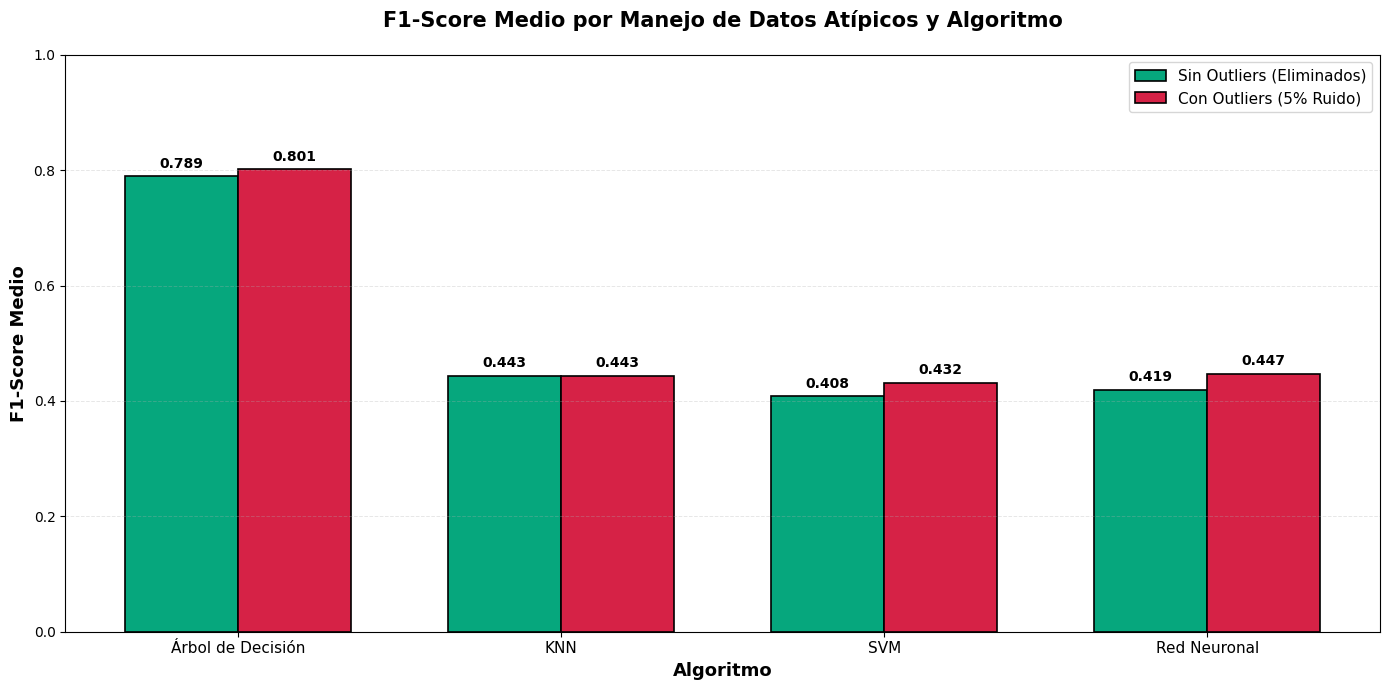

In [ ]:
# Nombres de los datasets SIN valores atípicos (eliminados)
datasets_sin_outliers = [
    "df_ED_no_outliers_balanced",
    "df_ED_no_outliers_unbalanced",
    "df_no_ED_no_outliers_balanced",
    "df_no_ED_no_outliers_unbalanced"
]

# Nombres de los datasets CON valores atípicos (5% ruido simulado)
datasets_con_outliers = [
    "df_ED_5pct_outliers_balanced",
    "df_ED_5pct_outliers_unbalanced",
    "df_no_ED_5pct_outliers_balanced",
    "df_no_ED_5pct_outliers_unbalanced"
]

# Diccionario con los dataframes de resultados y nombres de modelos
results_dict = {
    'Árbol de Decisión': results_arbol,
    'KNN': results_knn,
    'SVM': results_df_svm,
    'Red Neuronal': nn_result_df
}

# Calcular F1_Score medio para cada modelo
f1_scores_outliers = {
    'modelo': [],
    'sin_outliers': [],
    'con_outliers': []
}

for modelo_name, df_resultado in results_dict.items():
    # F1_Score medio SIN outliers (valores atípicos eliminados)
    f1_sin_outliers = df_resultado[df_resultado['Dataset'].isin(datasets_sin_outliers)]['F1_score'].mean()

    # F1_Score medio CON outliers (5% ruido simulado)
    f1_con_outliers = df_resultado[df_resultado['Dataset'].isin(datasets_con_outliers)]['F1_score'].mean()

    f1_scores_outliers['modelo'].append(modelo_name)
    f1_scores_outliers['sin_outliers'].append(f1_sin_outliers)
    f1_scores_outliers['con_outliers'].append(f1_con_outliers)

# Crear el gráfico de barras agrupadas
fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(f1_scores_outliers['modelo']))
width = 0.35

# Crear las barras
bars1 = ax.bar(x - width/2, f1_scores_outliers['sin_outliers'], width,
               label='Sin Outliers (Eliminados)', color='#06A77D', edgecolor='black', linewidth=1.2)
bars2 = ax.bar(x + width/2, f1_scores_outliers['con_outliers'], width,
               label='Con Outliers (5% Ruido)', color='#D62246', edgecolor='black', linewidth=1.2)

# Personalización del gráfico
ax.set_xlabel('Algoritmo', fontsize=13, fontweight='bold')
ax.set_ylabel('F1-Score Medio', fontsize=13, fontweight='bold')
ax.set_title('F1-Score Medio por Manejo de Datos Atípicos y Algoritmo',
             fontsize=15, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(f1_scores_outliers['modelo'], fontsize=11)
ax.legend(fontsize=11, loc='upper right')
ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
ax.set_ylim([0, 1.0])

# Añadir valores en las barras
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### Diagrama de barras con el F1-Score medio por balanceo y algoritmo

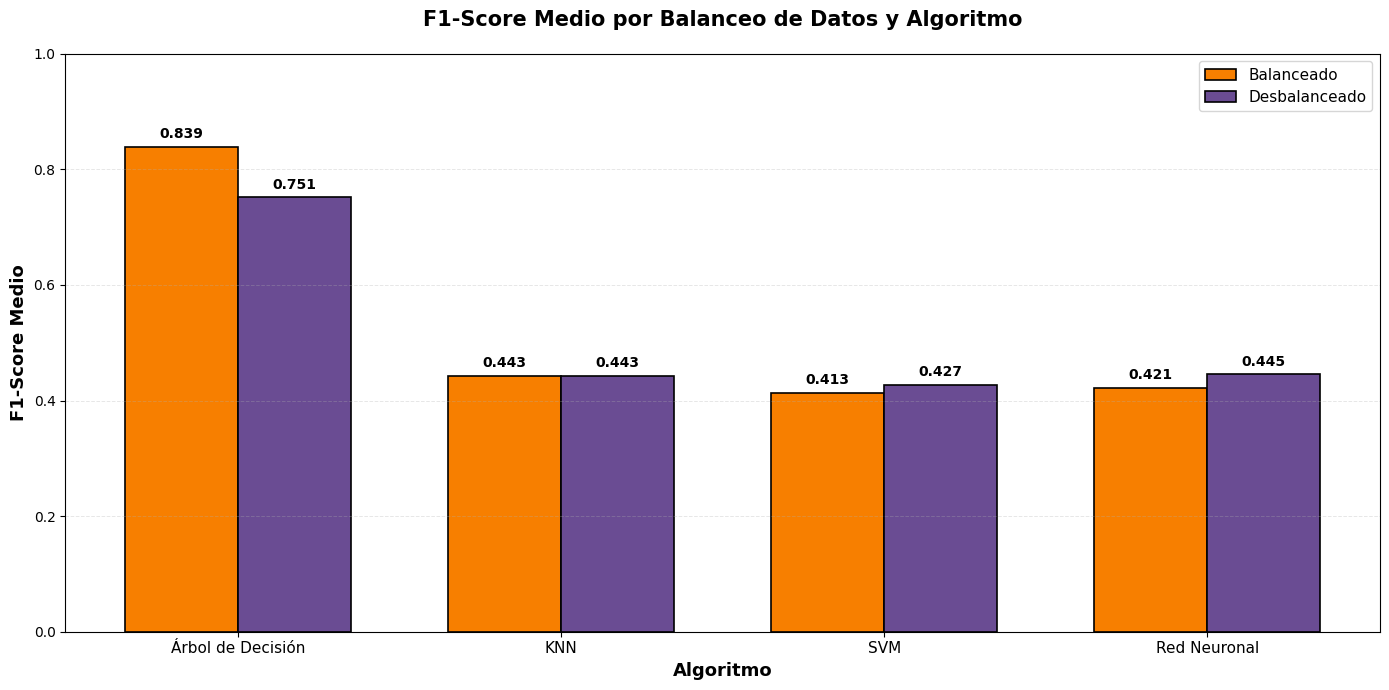

In [ ]:
# Nombres de los datasets BALANCEADOS
datasets_balanceados = [
    "df_ED_no_outliers_balanced",
    "df_ED_5pct_outliers_balanced",
    "df_no_ED_no_outliers_balanced",
    "df_no_ED_5pct_outliers_balanced"
]

# Nombres de los datasets DESBALANCEADOS
datasets_desbalanceados = [
    "df_ED_no_outliers_unbalanced",
    "df_ED_5pct_outliers_unbalanced",
    "df_no_ED_no_outliers_unbalanced",
    "df_no_ED_5pct_outliers_unbalanced"
]

# Diccionario con los dataframes de resultados y nombres de modelos
results_dict = {
    'Árbol de Decisión': results_arbol,
    'KNN': results_knn,
    'SVM': results_df_svm,
    'Red Neuronal': nn_result_df
}

# Calcular F1_Score medio para cada modelo
f1_scores_balance = {
    'modelo': [],
    'balanceado': [],
    'desbalanceado': []
}

for modelo_name, df_resultado in results_dict.items():
    # F1_Score medio con datos BALANCEADOS
    f1_balanceado = df_resultado[df_resultado['Dataset'].isin(datasets_balanceados)]['F1_score'].mean()

    # F1_Score medio con datos DESBALANCEADOS
    f1_desbalanceado = df_resultado[df_resultado['Dataset'].isin(datasets_desbalanceados)]['F1_score'].mean()

    f1_scores_balance['modelo'].append(modelo_name)
    f1_scores_balance['balanceado'].append(f1_balanceado)
    f1_scores_balance['desbalanceado'].append(f1_desbalanceado)

# Crear el gráfico de barras agrupadas
fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(f1_scores_balance['modelo']))
width = 0.35

# Crear las barras
bars1 = ax.bar(x - width/2, f1_scores_balance['balanceado'], width,
               label='Balanceado', color='#F77F00', edgecolor='black', linewidth=1.2)
bars2 = ax.bar(x + width/2, f1_scores_balance['desbalanceado'], width,
               label='Desbalanceado', color='#6A4C93', edgecolor='black', linewidth=1.2)

# Personalización del gráfico
ax.set_xlabel('Algoritmo', fontsize=13, fontweight='bold')
ax.set_ylabel('F1-Score Medio', fontsize=13, fontweight='bold')
ax.set_title('F1-Score Medio por Balanceo de Datos y Algoritmo',
             fontsize=15, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(f1_scores_balance['modelo'], fontsize=11)
ax.legend(fontsize=11, loc='upper right')
ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
ax.set_ylim([0, 1.0])

# Añadir valores en las barras
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

## **📈 ROC & Precision-Recall**

### obtenemos datos necesarios para los gráficos

In [ ]:
from itertools import cycle

# Seleccionar el dataset especifico
dataset_name = "df_ED_5pct_outliers_balanced"
data = train_test_data[dataset_name]

X_train = data["X_train"]
X_test = data["X_test"]
y_train = data["y_train"]
y_test = data["y_test"]


# Obtener las clases unicas
classes = sorted(y_train.unique())
n_classes = len(classes)

# Diccionarios para almacenar resultados
models_data = {}

# Entrenamos los modelos y obtenemos resultados
print("\nEntrenando modelos...")

# Árbol de decisión
from sklearn.tree import DecisionTreeClassifier
arbol = DecisionTreeClassifier(random_state=123)
arbol.fit(X_train, y_train)
y_proba_arbol = arbol.predict_proba(X_test)
models_data['Árbol de Decisión'] = {
    'model': arbol,
    'y_proba': y_proba_arbol,
    'y_pred': arbol.predict(X_test)
}

# KNN
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_proba_knn = knn.predict_proba(X_test)
models_data['KNN'] = {
    'model': knn,
    'y_proba': y_proba_knn,
    'y_pred': knn.predict(X_test)
}

# SVM
from sklearn.svm import SVC
svm = SVC(probability=True, random_state=123)
svm.fit(X_train, y_train)
y_proba_svm = svm.predict_proba(X_test)
models_data['SVM'] = {
    'model': svm,
    'y_proba': y_proba_svm,
    'y_pred': svm.predict(X_test)
}

# Redes neuronales
from sklearn.neural_network import MLPClassifier
nn = MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=123)
nn.fit(X_train, y_train)
y_proba_nn = nn.predict_proba(X_test)
models_data['Red Neuronal'] = {
    'model': nn,
    'y_proba': y_proba_nn,
    'y_pred': nn.predict(X_test)
}

print("¡Entrenamiento completado!")


Entrenando modelos...
¡Entrenamiento completado!


### ROC

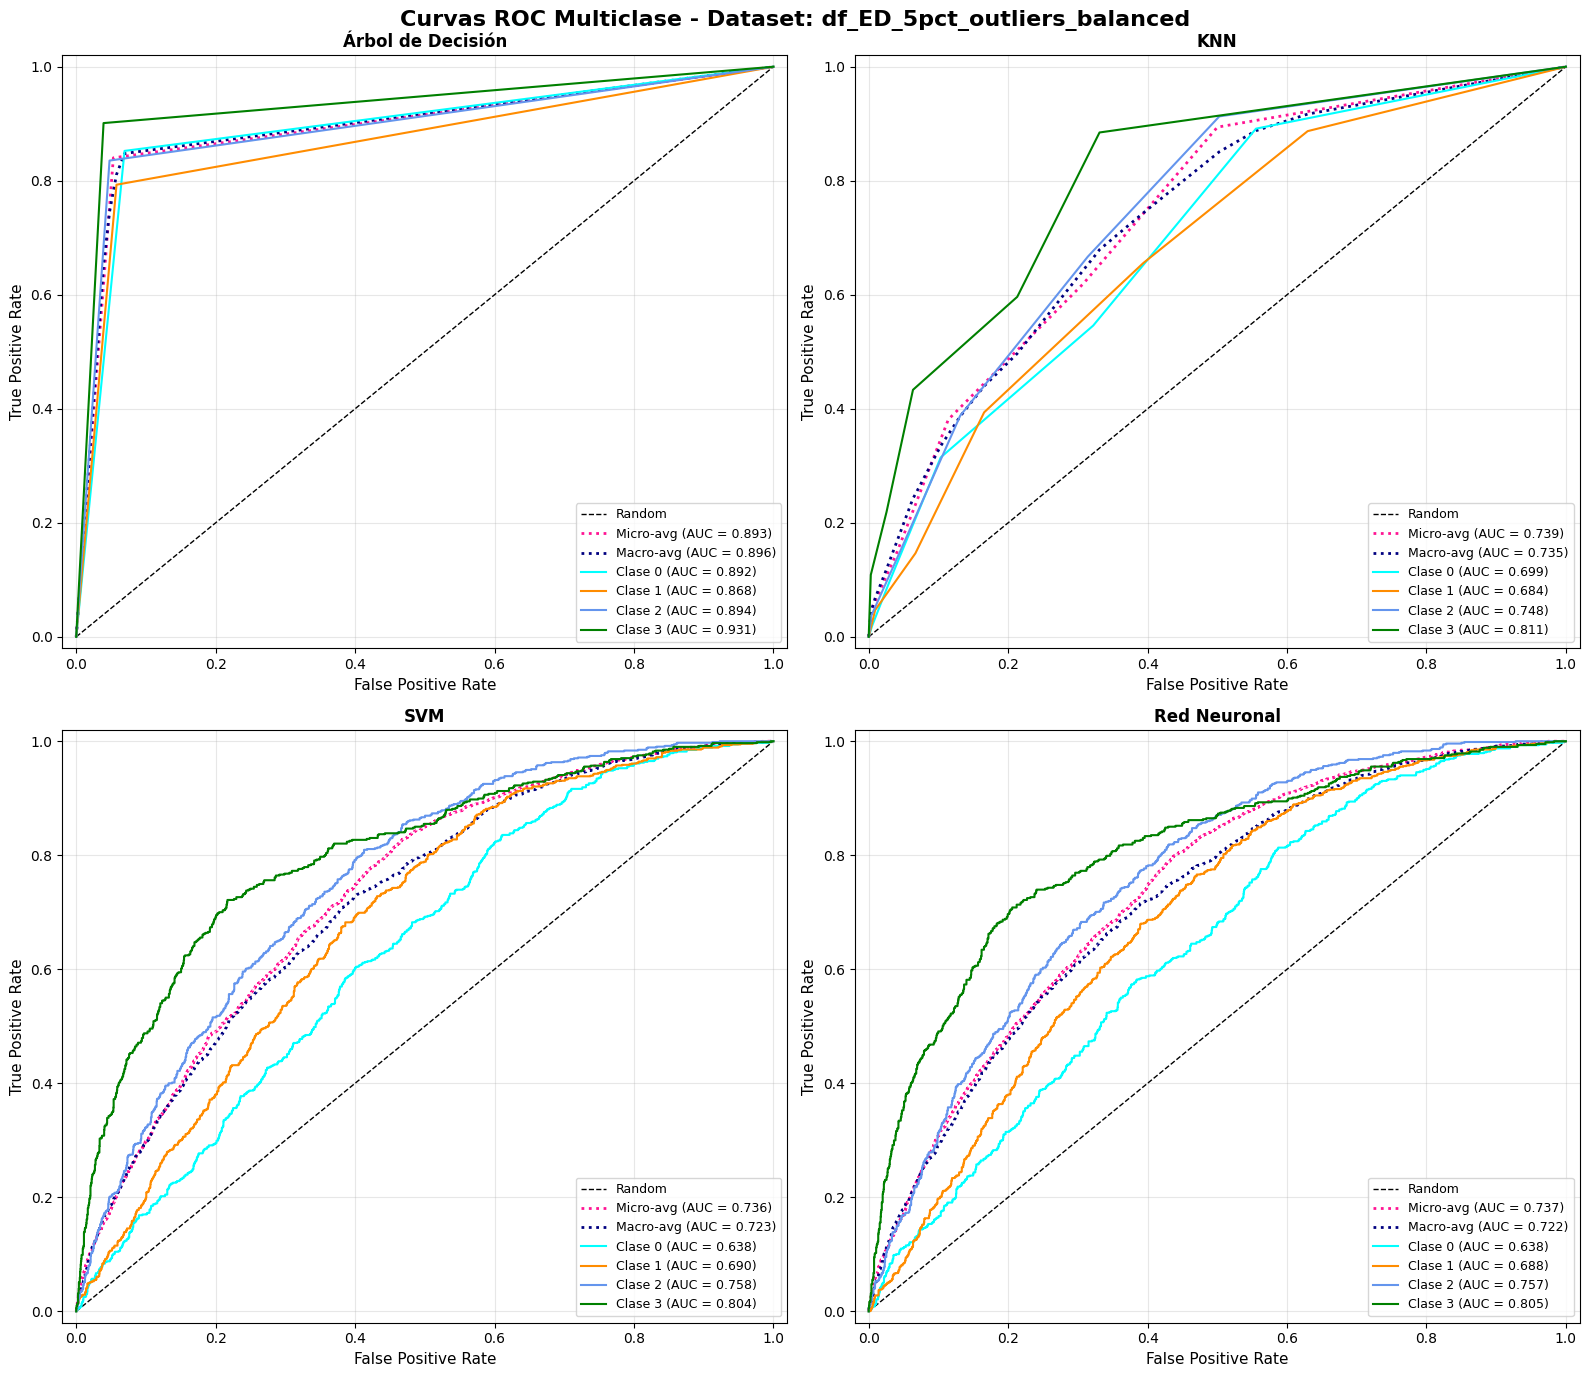

In [ ]:
# Binarizar las etiquetas para el enfoque One-vs-Rest
y_test_binarized = label_binarize(y_test, classes=classes)

# Configuración de colores
colors_models = {
    'Árbol de Decisión': '#FF6B6B',
    'KNN': '#4ECDC4',
    'SVM': '#45B7D1',
    'Red Neuronal': '#96CEB4'
}

# Crear figura para curvas ROC
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
fig.suptitle(f'Curvas ROC Multiclase - Dataset: {dataset_name}', fontsize=16, fontweight='bold')

for idx, (model_name, model_data) in enumerate(models_data.items()):
    ax = axes[idx // 2, idx % 2]

    y_proba = model_data['y_proba']

    # Calcular ROC curve y AUC para cada clase
    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_binarized[:, i], y_proba[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Calcular micro-average ROC curve y AUC
    fpr["micro"], tpr["micro"], _ = roc_curve(y_test_binarized.ravel(), y_proba.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

    # Calcular macro-average ROC curve y AUC
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes
    fpr["macro"] = all_fpr
    tpr["macro"] = mean_tpr
    roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

    # Graficar curvas
    # Línea de referencia
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random')

    # Micro-average
    ax.plot(fpr["micro"], tpr["micro"],
            label=f'Micro-avg (AUC = {roc_auc["micro"]:.3f})',
            color='deeppink', linestyle=':', linewidth=2)

    # Macro-average
    ax.plot(fpr["macro"], tpr["macro"],
            label=f'Macro-avg (AUC = {roc_auc["macro"]:.3f})',
            color='navy', linestyle=':', linewidth=2)

    # Curvas individuales por clase
    colors_cycle = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red', 'purple'])
    for i, color in zip(range(n_classes), colors_cycle):
        ax.plot(fpr[i], tpr[i], color=color, lw=1.5,
                label=f'Clase {classes[i]} (AUC = {roc_auc[i]:.3f})')

    ax.set_xlim([-0.02, 1.02])
    ax.set_ylim([-0.02, 1.02])
    ax.set_xlabel('False Positive Rate', fontsize=11)
    ax.set_ylabel('True Positive Rate', fontsize=11)
    ax.set_title(f'{model_name}', fontsize=12, fontweight='bold')
    ax.legend(loc="lower right", fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Precision - Recall

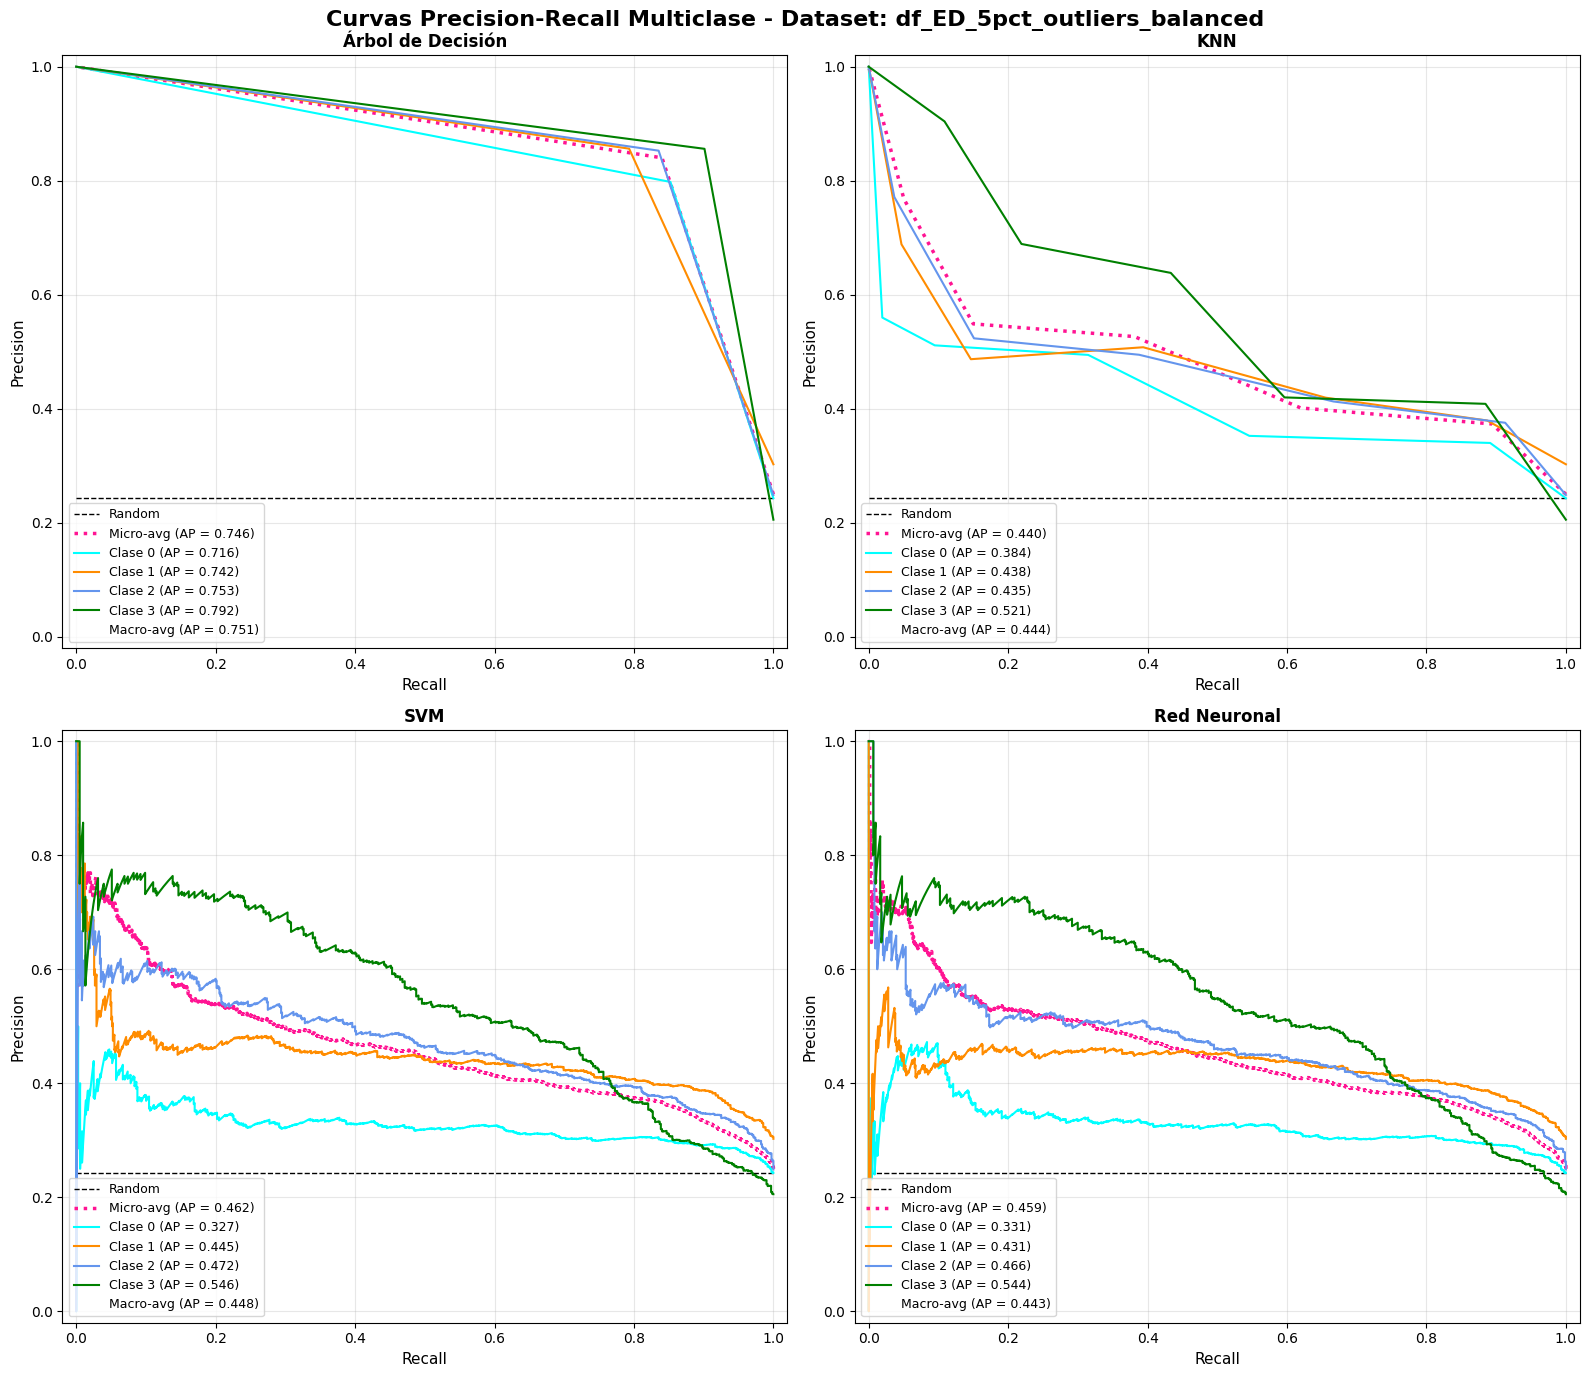

In [ ]:
# Curvas Precision-Recall por modelo
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
fig.suptitle(f'Curvas Precision-Recall Multiclase - Dataset: {dataset_name}',
             fontsize=16, fontweight='bold')

# Binarizar las etiquetas
y_test_binarized = label_binarize(y_test, classes=classes)

for idx, (model_name, model_data) in enumerate(models_data.items()):
    ax = axes[idx // 2, idx % 2]

    y_proba = model_data['y_proba']

    # Diccionarios para almacenar precision, recall y average precision
    precision = dict()
    recall = dict()
    average_precision = dict()

    # Calcular Precision-Recall para cada clase
    for i in range(n_classes):
        precision[i], recall[i], _ = precision_recall_curve(
            y_test_binarized[:, i], y_proba[:, i]
        )
        average_precision[i] = average_precision_score(
            y_test_binarized[:, i], y_proba[:, i]
        )

    # Calcular micro-average Precision-Recall
    precision["micro"], recall["micro"], _ = precision_recall_curve(
        y_test_binarized.ravel(), y_proba.ravel()
    )
    average_precision["micro"] = average_precision_score(
        y_test_binarized, y_proba, average="micro"
    )

    # Calcular macro-average Precision-Recall
    average_precision["macro"] = average_precision_score(
        y_test_binarized, y_proba, average="macro"
    )

    # Graficar curvas
    no_skill = len(y_test[y_test==classes[0]]) / len(y_test)  # proporción de clase positiva
    ax.plot([0, 1], [no_skill, no_skill], 'k--', lw=1, label='Random')

    # Micro-average
    ax.plot(recall["micro"], precision["micro"],
            label=f'Micro-avg (AP = {average_precision["micro"]:.3f})',
            color='deeppink', linestyle=':', linewidth=2.5)

    # Curvas individuales por clase
    colors_cycle = cycle(['aqua', 'darkorange', 'cornflowerblue',
                         'green', 'red', 'purple', 'yellow', 'brown'])

    for i, color in zip(range(n_classes), colors_cycle):
        ax.plot(recall[i], precision[i], color=color, lw=1.5,
                label=f'Clase {classes[i]} (AP = {average_precision[i]:.3f})')

    # Añadir línea para macro-average
    ax.plot([], [], ' ', label=f'Macro-avg (AP = {average_precision["macro"]:.3f})')

    ax.set_xlim([-0.02, 1.02])
    ax.set_ylim([-0.02, 1.02])
    ax.set_xlabel('Recall', fontsize=11)
    ax.set_ylabel('Precision', fontsize=11)
    ax.set_title(f'{model_name}', fontsize=12, fontweight='bold')
    ax.legend(loc="lower left", fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Aprendizaje No Supervisado (K-Means y DBSCAN)

In [ ]:
%pip install imbalanced-learn

## 2.1 Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from scipy import stats
from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings("ignore")

# Semilla elegida por el grupo (≠ 42)
RANDOM_STATE = 123

## 2.2 Cargar dataset

In [ ]:
DATA_PATH = "../data/matches_2014_2024.csv"
SUBSET_SIZE = 5800  # filas usadas en el análisis no supervisado

df_full = pd.read_csv(DATA_PATH, parse_dates=['datetime'])
N = SUBSET_SIZE

df_subset = df_full.iloc[:N].reset_index(drop=True)
df_subset.head(), df_subset.shape

(     id  season league            datetime             home_team    away_team  \
 0  4749    2014    EPL 2014-08-16 12:45:00     Manchester United      Swansea   
 1  4750    2014    EPL 2014-08-16 15:00:00             Leicester      Everton   
 2  4751    2014    EPL 2014-08-16 15:00:00   Queens Park Rangers         Hull   
 3  4752    2014    EPL 2014-08-16 15:00:00                 Stoke  Aston Villa   
 4  4753    2014    EPL 2014-08-16 15:00:00  West Bromwich Albion   Sunderland   
 
    goals_h  goals_a      xG_h      xG_a  forecast_w  forecast_d  forecast_l  \
 0      1.0      2.0  1.166350  0.278076      0.6519      0.2802      0.0679   
 1      2.0      2.0  1.278300  0.613273      0.5513      0.2922      0.1565   
 2      0.0      1.0  1.900670  1.117570      0.5900      0.2449      0.1651   
 3      0.0      1.0  0.423368  0.909774      0.1468      0.3637      0.4895   
 4      2.0      2.0  1.683430  0.991901      0.5894      0.2676      0.1430   
 
    target  
 0       2 

## 2.3 Guardar subset_datos.csv

In [ ]:
df_subset.to_csv("subset_datos.csv", index=False)

print("Archivo 'subset_datos.csv' creado correctamente con las primeras", len(df_subset), "filas.")

Archivo 'subset_datos.csv' creado correctamente con las primeras 5800 filas.


## 2.4 Eliminar variable objetivo y crear subset_no_target.csv

In [ ]:
target_col = "target"

df_no_target = df_subset.drop(columns=[target_col])
df_no_target.to_csv("subset_no_target.csv", index=False)

print("subset_no_target.csv creado (sin columna target) ✔️")
df_no_target.head()

subset_no_target.csv creado (sin columna target) ✔️


,id,season,league,datetime,home_team,away_team,goals_h,goals_a,xG_h,xG_a,forecast_w,forecast_d,forecast_l
0,4749,2014,EPL,2014-08-16 12:45:00,Manchester United,Swansea,1.0,2.0,1.166350,0.278076,0.6519,0.2802,0.0679
1,4750,2014,EPL,2014-08-16 15:00:00,Leicester,Everton,2.0,2.0,1.278300,0.613273,0.5513,0.2922,0.1565
2,4751,2014,EPL,2014-08-16 15:00:00,Queens Park Rangers,Hull,0.0,1.0,1.900670,1.117570,0.5900,0.2449,0.1651
3,4752,2014,EPL,2014-08-16 15:00:00,Stoke,Aston Villa,0.0,1.0,0.423368,0.909774,0.1468,0.3637,0.4895
4,4753,2014,EPL,2014-08-16 15:00:00,West Bromwich Albion,Sunderland,2.0,2.0,1.683430,0.991901,0.5894,0.2676,0.1430


## 2.5 Carga del dataset y definición de los 8 casos

In [ ]:
# Cargar dataset base SIN variable objetivo
df_base = pd.read_csv("subset_no_target.csv", parse_dates=["datetime"])
print("✅ Dataset base cargado:", df_base.shape)

# Definir variables categóricas
cat_cols = ["league", "home_team", "away_team"]

# One-Hot Encoding (CC = Sí siempre)
df_encoded = pd.get_dummies(df_base, columns=cat_cols, drop_first=True)

# Eliminar columnas no útiles para clustering
df_encoded = df_encoded.drop(columns=["datetime", "id"], errors="ignore")

# Definición de los 8 casos
cases = {
    1: {"ED": False, "OUT": False, "BAL": False},
    2: {"ED": False, "OUT": False, "BAL": True},
    3: {"ED": False, "OUT": True,  "BAL": False},
    4: {"ED": False, "OUT": True,  "BAL": True},
    5: {"ED": True,  "OUT": False, "BAL": False},
    6: {"ED": True,  "OUT": False, "BAL": True},
    7: {"ED": True,  "OUT": True,  "BAL": False},
    8: {"ED": True,  "OUT": True,  "BAL": True},
}

# Nota: En aprendizaje NO supervisado, BAL=Sí solo se mantiene como condición experimental,
# no se aplica duplicación de filas ni SMOTE porque no hay variable objetivo.

✅ Dataset base cargado: (5800, 13)


## 2.6 Funciones auxiliares (Outliers + Escalado)

In [ ]:
# Función para añadir outliers artificiales (~5% de las filas)
def add_outliers(df, frac=0.05, magnitude=8, seed=RANDOM_STATE):
    np.random.seed(seed)
    df_out = df.copy()
    n_rows = df_out.shape[0]
    n_out = int(frac * n_rows)
    idx = np.random.choice(df_out.index, size=n_out, replace=False)
    for c in df_out.columns:
        ruido = np.random.normal(0, df_out[c].std() * magnitude, size=n_out)
        df_out.loc[idx, c] = df_out.loc[idx, c] + ruido
    return df_out

# Escalado opcional
def scale_data(df, use_scaler):
    if use_scaler:
        scaler = StandardScaler()
        return pd.DataFrame(scaler.fit_transform(df), columns=df.columns)
    return df.copy()

## 2.7 Función para entrenar y evaluar un caso (K-MEANS - DBSCAN)

In [ ]:
def train_case(case_id, conf, df_input):
    print("\n" + "="*60)
    print(f"🧩 CASE {case_id} | ED={conf['ED']} | OUTLIERS={conf['OUT']} | BAL={conf['BAL']}")

    df_case = df_input.copy()

    # Outliers
    if conf["OUT"]:
        df_case = add_outliers(df_case, seed=RANDOM_STATE + case_id)
        print(" → Outliers añadidos (~5%)")

    # Escalado
    df_scaled = scale_data(df_case, conf["ED"])
    print(f" → {'Con' if conf['ED'] else 'Sin'} escalado")

    # K-MEANS
    inertias, silhouettes = [], []
    for k in range(2, 10):
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        labels = km.fit_predict(df_scaled)
        inertias.append(km.inertia_)
        silhouettes.append(silhouette_score(df_scaled, labels))

    plt.figure(figsize=(6, 3))
    plt.plot(range(2, 10), inertias, "o-")
    plt.title(f"CASE {case_id} - Método del Codo (K-Means)")
    plt.xlabel("k")
    plt.ylabel("Inercia")
    plt.show()

    best_k = np.argmax(silhouettes) + 2
    kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
    labels_km = kmeans.fit_predict(df_scaled)
    sil_km = silhouette_score(df_scaled, labels_km)

    print(f"✅ K-Means → k={best_k}, Silhouette={sil_km:.4f}")


    # DBSCAN
    neigh = NearestNeighbors(n_neighbors=5)
    neigh.fit(df_scaled)
    distances, _ = neigh.kneighbors(df_scaled)
    distances = np.sort(distances[:, 4])

    plt.figure(figsize=(6, 3))
    plt.plot(distances)
    plt.title(f"CASE {case_id} - Distancia k-NN (para ε)")
    plt.show()

    # Mejor ε por percentil + grid local
    eps_base = np.percentile(distances, 90)
    eps_candidates = np.linspace(eps_base*0.8, eps_base*1.2, 5)
    best_eps, best_sil = eps_base, -1
    for eps in eps_candidates:
        db = DBSCAN(eps=eps, min_samples=5)
        labels = db.fit_predict(df_scaled)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        if n_clusters > 1:
            sil = silhouette_score(df_scaled, labels)
            if sil > best_sil:
                best_eps, best_sil = eps, sil

    db = DBSCAN(eps=best_eps, min_samples=5)
    labels_db = db.fit_predict(df_scaled)
    n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
    sil_db = silhouette_score(df_scaled, labels_db) if n_clusters_db > 1 else -1

    print(f"✅ DBSCAN → ε={best_eps:.3f}, Clusters={n_clusters_db}, Silhouette={sil_db:.4f}")

    # Visualización PCA
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    reduced = pca.fit_transform(df_scaled)

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].scatter(reduced[:, 0], reduced[:, 1], c=labels_km, cmap="tab10", s=10)
    ax[0].set_title(f"K-Means (k={best_k})")
    ax[1].scatter(reduced[:, 0], reduced[:, 1], c=labels_db, cmap="tab10", s=10)
    ax[1].set_title("DBSCAN")
    plt.show()

    return {
        "Caso": case_id,
        "Normalización": "Sí" if conf["ED"] else "No",
        "Outliers": "Sí" if conf["OUT"] else "No",
        "Balanceo": "Sí" if conf["BAL"] else "No",
        "KMeans_k": best_k,
        "Silhouette_KMeans": sil_km,
        "Clusters_DBSCAN": n_clusters_db,
        "Silhouette_DBSCAN": sil_db,
    }

## 2.8 Ejecutar los 8 casos y comparar resultados


🧩 CASE 1 | ED=False | OUTLIERS=False | BAL=False
 → Sin escalado


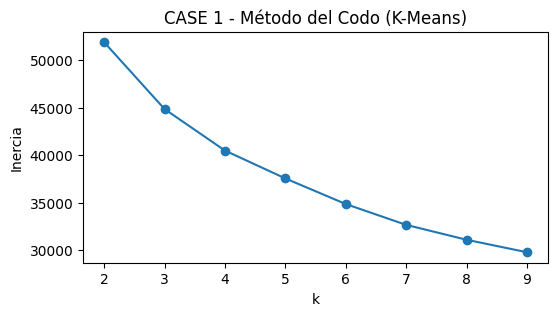

✅ K-Means → k=2, Silhouette=0.3871


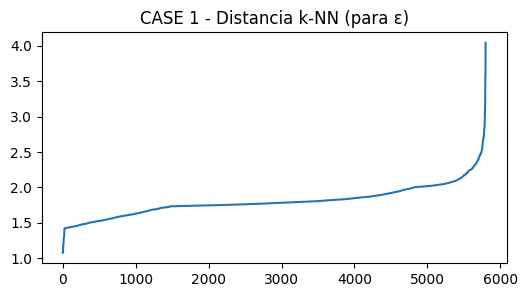

✅ DBSCAN → ε=2.046, Clusters=3, Silhouette=0.0695


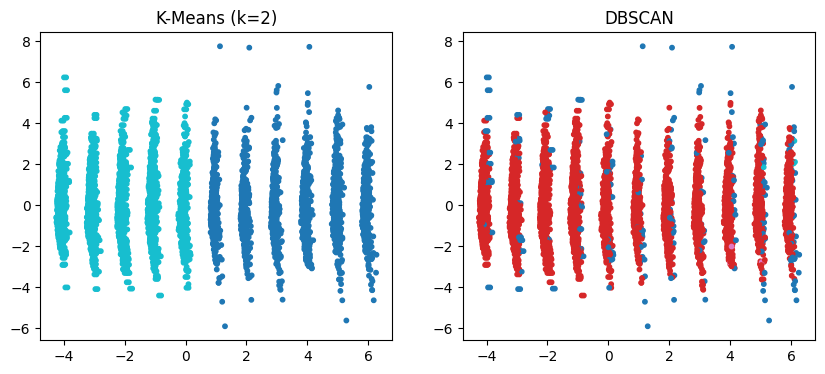


🧩 CASE 2 | ED=False | OUTLIERS=False | BAL=True
 → Sin escalado


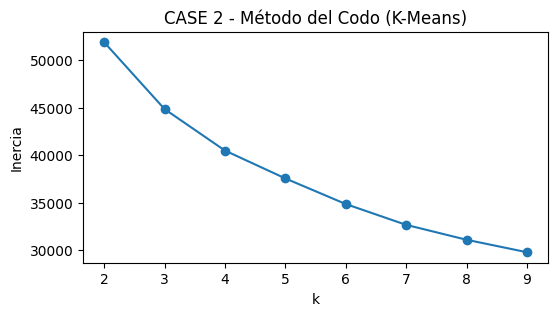

✅ K-Means → k=2, Silhouette=0.3871


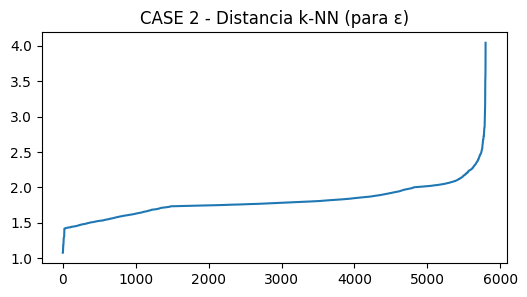

✅ DBSCAN → ε=2.046, Clusters=3, Silhouette=0.0695


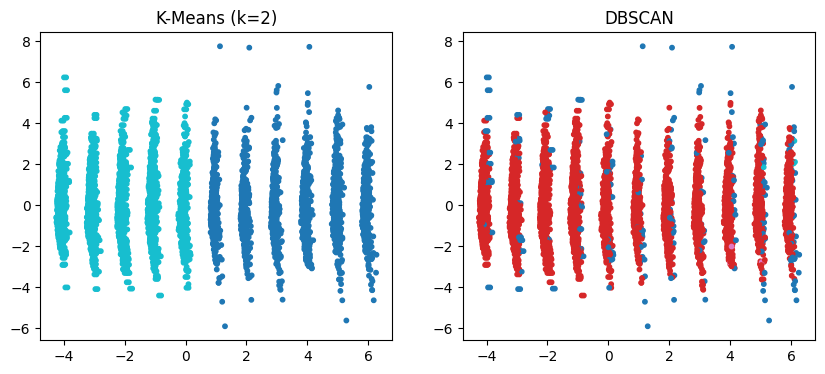


🧩 CASE 3 | ED=False | OUTLIERS=True | BAL=False
 → Outliers añadidos (~5%)
 → Sin escalado


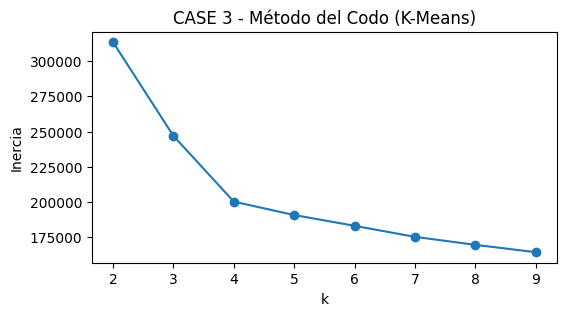

✅ K-Means → k=2, Silhouette=0.8052


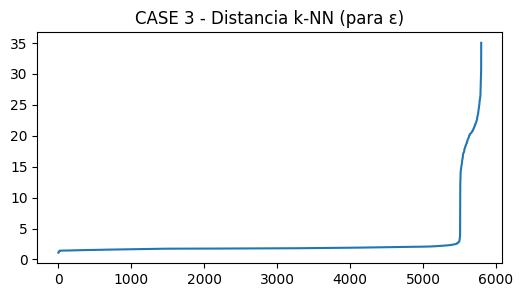

✅ DBSCAN → ε=1.955, Clusters=4, Silhouette=-0.1314


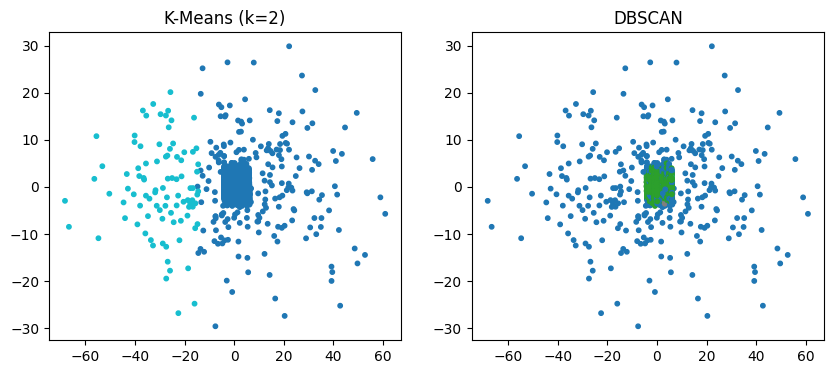


🧩 CASE 4 | ED=False | OUTLIERS=True | BAL=True
 → Outliers añadidos (~5%)
 → Sin escalado


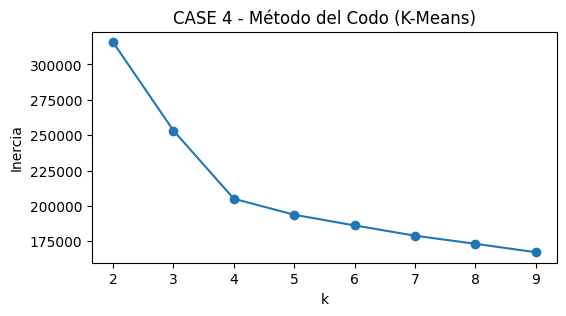

✅ K-Means → k=2, Silhouette=0.8020


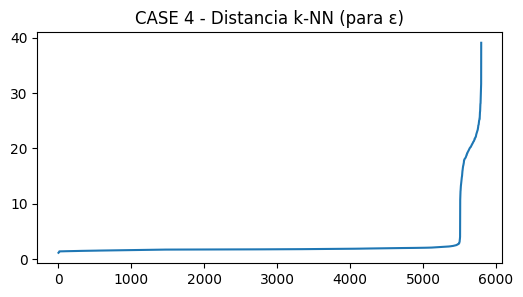

✅ DBSCAN → ε=1.954, Clusters=5, Silhouette=-0.1554


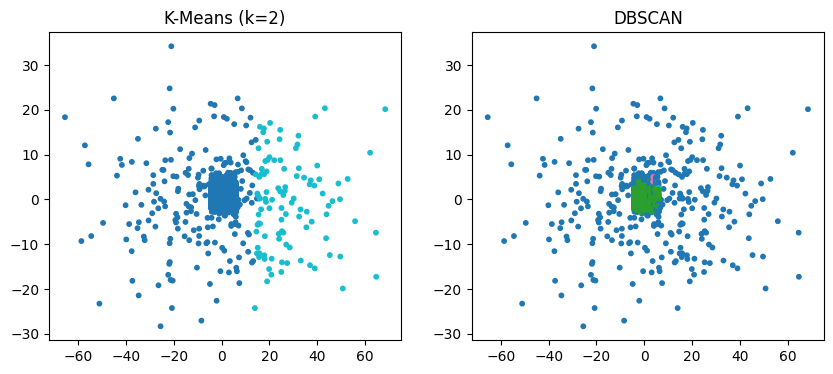


🧩 CASE 5 | ED=True | OUTLIERS=False | BAL=False
 → Con escalado


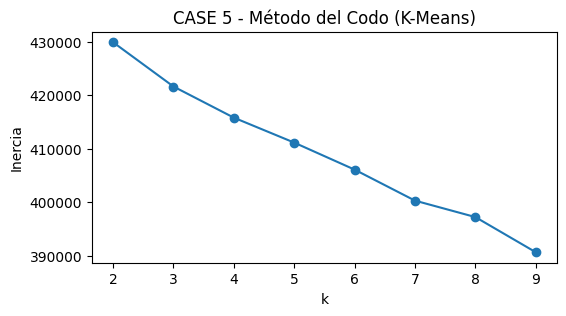

✅ K-Means → k=2, Silhouette=0.0403


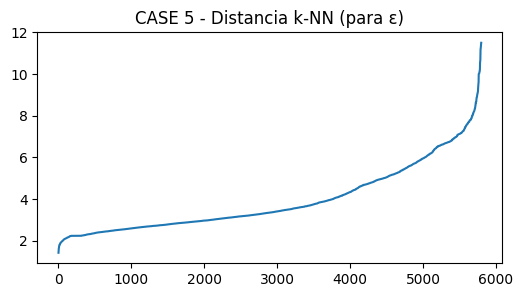

✅ DBSCAN → ε=7.856, Clusters=25, Silhouette=0.2100


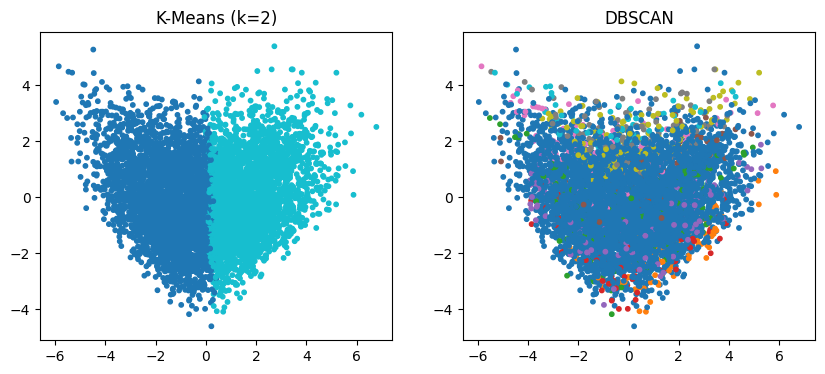


🧩 CASE 6 | ED=True | OUTLIERS=False | BAL=True
 → Con escalado


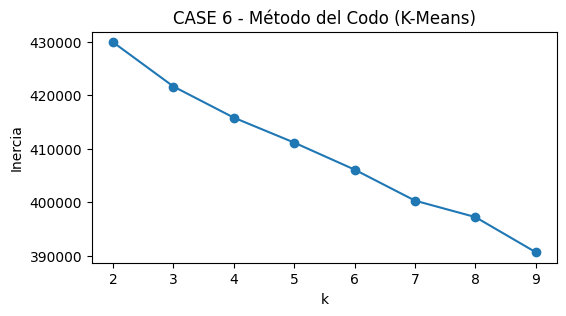

✅ K-Means → k=2, Silhouette=0.0403


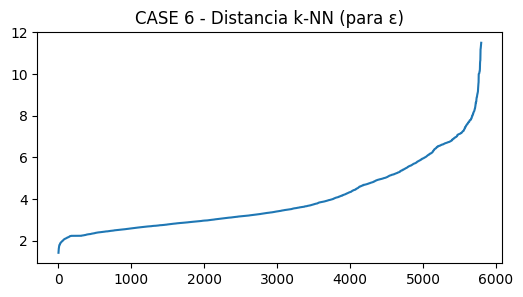

✅ DBSCAN → ε=7.856, Clusters=25, Silhouette=0.2100


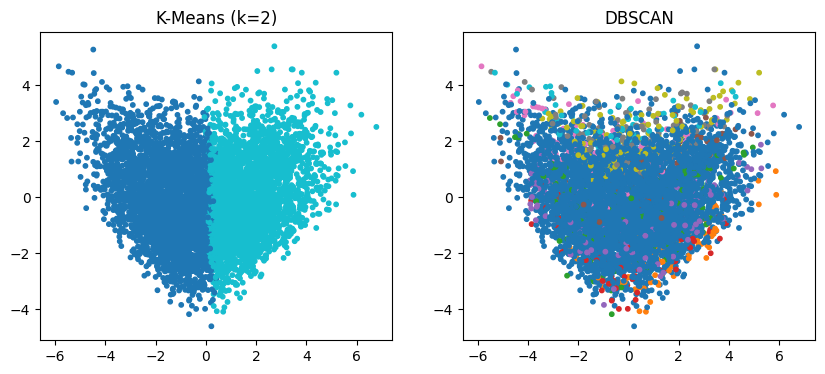


🧩 CASE 7 | ED=True | OUTLIERS=True | BAL=False
 → Outliers añadidos (~5%)
 → Con escalado


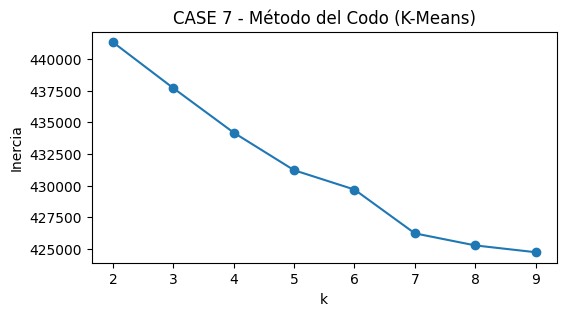

✅ K-Means → k=4, Silhouette=0.6401


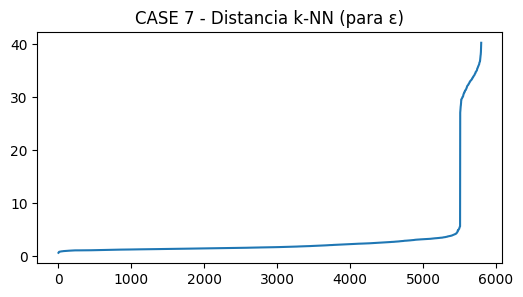

✅ DBSCAN → ε=4.175, Clusters=25, Silhouette=0.1880


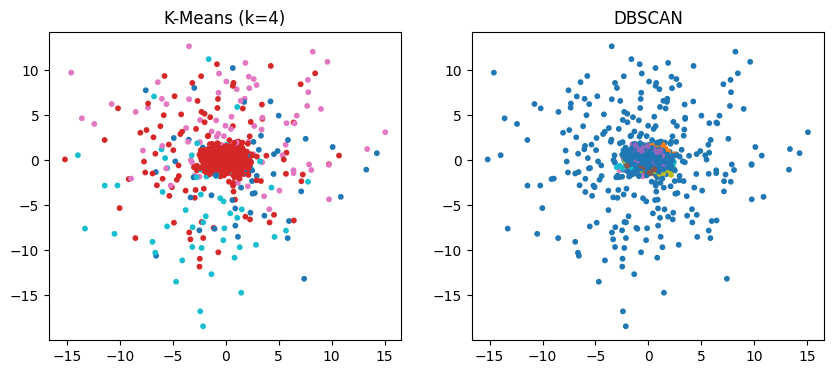


🧩 CASE 8 | ED=True | OUTLIERS=True | BAL=True
 → Outliers añadidos (~5%)
 → Con escalado


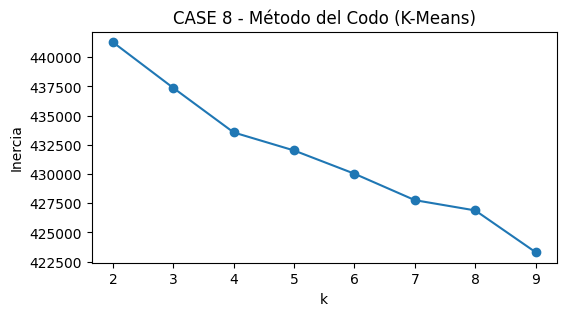

✅ K-Means → k=3, Silhouette=0.0391


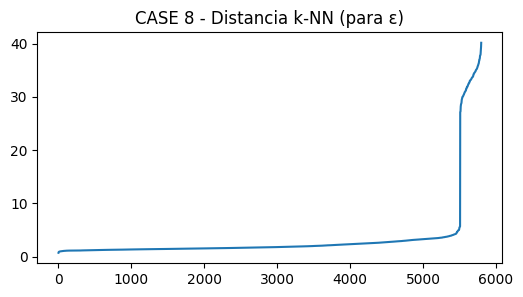

✅ DBSCAN → ε=4.193, Clusters=23, Silhouette=0.1756


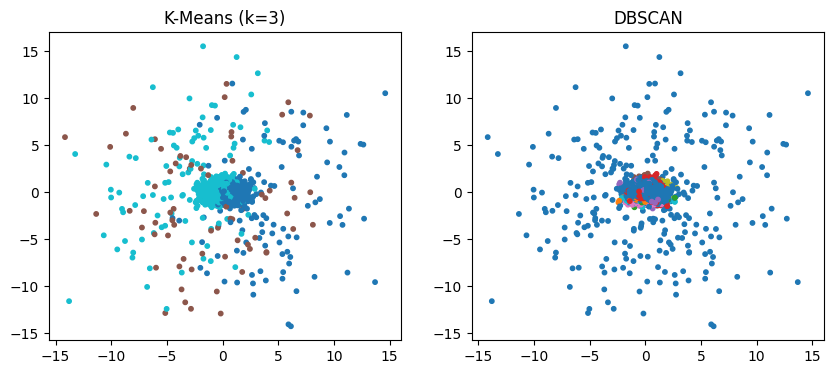


📊 RESULTADOS GLOBALES


,Caso,Normalización,Outliers,Balanceo,KMeans_k,Silhouette_KMeans,Clusters_DBSCAN,Silhouette_DBSCAN
0,1,No,No,No,2,0.387095,3,0.069490
1,2,No,No,Sí,2,0.387095,3,0.069490
2,3,No,Sí,No,2,0.805191,4,-0.131443
3,4,No,Sí,Sí,2,0.801983,5,-0.155376
4,5,Sí,No,No,2,0.040327,25,0.210046
5,6,Sí,No,Sí,2,0.040327,25,0.210046
6,7,Sí,Sí,No,4,0.640099,25,0.187967
7,8,Sí,Sí,Sí,3,0.039131,23,0.175625


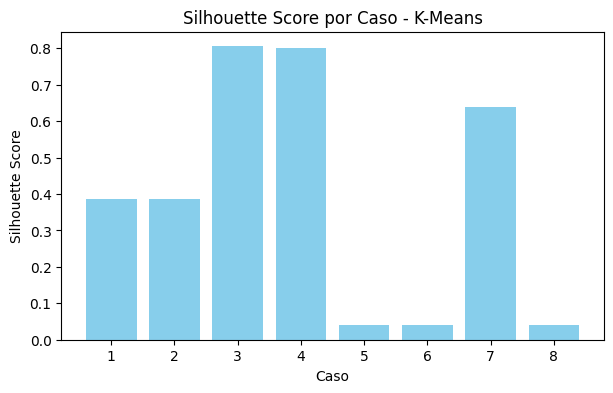

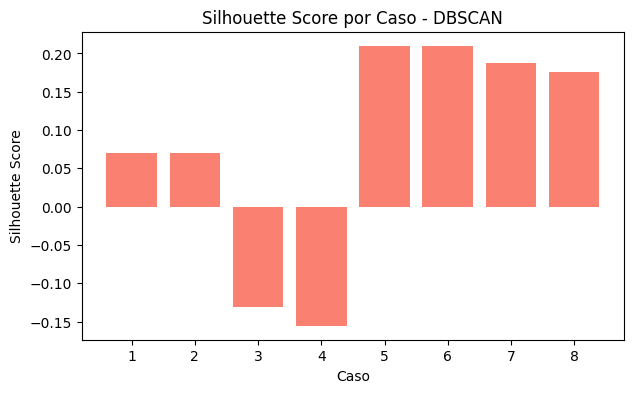

In [ ]:
results = []
for case_id, conf in cases.items():
    results.append(train_case(case_id, conf, df_encoded))

df_results = pd.DataFrame(results)
print("\n📊 RESULTADOS GLOBALES")
display(df_results)

plt.figure(figsize=(7, 4))
plt.bar(df_results["Caso"], df_results["Silhouette_KMeans"], color="skyblue")
plt.title("Silhouette Score por Caso - K-Means")
plt.xlabel("Caso")
plt.ylabel("Silhouette Score")
plt.show()

plt.figure(figsize=(7, 4))
plt.bar(df_results["Caso"], df_results["Silhouette_DBSCAN"], color="salmon")
plt.title("Silhouette Score por Caso - DBSCAN")
plt.xlabel("Caso")
plt.ylabel("Silhouette Score")
plt.show()